# DSCI 552 — Homework 7

**Name:** Ellie He
**Course:** DSCI 552 — Machine Learning for Data Science (Instructor: Mohammad Reza Rajati)
**Assignment:** Homework 7 — Multi-class / Multi-label Classification with SVMs, K-Means Clustering

**Contents**
1. Multi-class and multi-label classification using support vector machines (parts a, b.i–b.vi)
2. K-means clustering on a multi-class and multi-label data set (Monte-Carlo simulation, parts a–c)
3. ISLR 12.6.2

In [1]:
import os, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, confusion_matrix, precision_score, recall_score,
                             roc_auc_score, roc_curve, accuracy_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from scipy.cluster.hierarchy import dendrogram

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 140)
sns.set_style("whitegrid")

# 1. Multi-class and Multi-Label Classification Using Support Vector Machines

## (a) Data and train/test split

The Anuran Calls (MFCCs) data set was downloaded from the UCI Machine Learning Repository. It has 7,195 frog-call syllables, 22 MFCC features, and three labels: `Family`, `Genus`, and `Species` (`RecordID` is an identifier and is not used). 70% of the rows are chosen at random as the training set; the remaining 30% form the test set.

In [2]:
# Look for the CSV in ../data, ./data, or the current folder
DATA_DIR = next(d for d in ["../data", "data", "."] if os.path.exists(os.path.join(d, "Frogs_MFCCs.csv")))
df = pd.read_csv(os.path.join(DATA_DIR, "Frogs_MFCCs.csv"))

feat_cols = [c for c in df.columns if c.startswith("MFCCs")]
LABELS = ["Family", "Genus", "Species"]
X_all = df[feat_cols].values
Y_all = df[LABELS]

print("Shape:", df.shape, "| features:", len(feat_cols))
for lab in LABELS:
    print(f"\n{lab} ({df[lab].nunique()} classes):")
    print(df[lab].value_counts().to_string())

Shape: (7195, 26) | features: 22

Family (4 classes):
Family
Leptodactylidae    4420
Hylidae            2165
Dendrobatidae       542
Bufonidae            68

Genus (8 classes):
Genus
Adenomera        4150
Hypsiboas        1593
Ameerega          542
Dendropsophus     310
Leptodactylus     270
Scinax            148
Osteocephalus     114
Rhinella           68

Species (10 classes):
Species
AdenomeraHylaedactylus    3478
HypsiboasCordobae         1121
AdenomeraAndre             672
Ameeregatrivittata         542
HypsiboasCinerascens       472
HylaMinuta                 310
LeptodactylusFuscus        270
ScinaxRuber                148
OsteocephalusOophagus      114
Rhinellagranulosa           68


In [3]:
X_train, X_test, Y_train, Y_test = train_test_split(X_all, Y_all, train_size=0.7, random_state=SEED)
Y_train = Y_train.reset_index(drop=True); Y_test = Y_test.reset_index(drop=True)
print("Training set:", X_train.shape, " Test set:", X_test.shape)
print("\nFeature ranges (the MFCCs are already scaled to [-1, 1]):")
print(pd.DataFrame(X_train, columns=feat_cols).describe().loc[["mean", "std", "min", "max"]].round(3).iloc[:, :8])

Training set: (5036, 22)  Test set: (2159, 22)

Feature ranges (the MFCCs are already scaled to [-1, 1]):
      MFCCs_ 1  MFCCs_ 2  MFCCs_ 3  MFCCs_ 4  MFCCs_ 5  MFCCs_ 6  MFCCs_ 7  MFCCs_ 8
mean     0.989     0.327     0.312     0.447     0.129     0.097    -0.005     0.001
std      0.074     0.221     0.264     0.159     0.161     0.121     0.168     0.116
min     -0.251    -0.616    -0.436    -0.351    -0.567    -0.410    -0.383    -0.577
max      1.000     1.000     1.000     1.000     0.752     0.964     0.935     0.552


## (b) Binary relevance: one classifier per label

### i. Exact match and Hamming score / loss

Each instance $i$ has a true label vector $\mathbf y_i = (y_{i1}, y_{i2}, y_{i3})$ = (family, genus, species) and a predicted vector $\hat{\mathbf y}_i$. With $N$ instances and $L = 3$ labels:

- **Exact match ratio (subset accuracy).** The fraction of instances whose *whole* label vector is predicted correctly:
$$\text{EM} = \frac{1}{N}\sum_{i=1}^{N} \mathbb 1\big[\hat{\mathbf y}_i = \mathbf y_i\big].$$
This is the strictest measure: one wrong label makes the whole instance count as wrong.

- **Hamming distance** of an instance: the number of label positions where the prediction differs from the truth, $d_H(\mathbf y_i, \hat{\mathbf y}_i) = \sum_{j=1}^{L} \mathbb 1[\hat y_{ij} \neq y_{ij}] \in \{0, 1, 2, 3\}$.

- **Hamming loss.** The fraction of individual labels predicted wrongly, averaged over instances and labels:
$$\text{HL} = \frac{1}{NL}\sum_{i=1}^{N}\sum_{j=1}^{L}\mathbb 1\big[\hat y_{ij}\neq y_{ij}\big] = \frac{1}{NL}\sum_i d_H(\mathbf y_i,\hat{\mathbf y}_i).$$
Unlike exact match, it gives partial credit (getting 2 of 3 labels right costs $1/3$, not $1$). Lower is better.

- **Hamming score.** In this multi-output setting, the Hamming score is the fraction of labels predicted correctly, $\text{HS} = 1 - \text{HL}$ (the average per-label accuracy). Higher is better.

**Set-based (Godbole & Sarawagi) Hamming score.** In the multi-label literature (e.g. Sorower, *A Literature Survey on Algorithms for Multi-label Learning*), labels are often written as a set $Y_i$ of relevant labels out of all $4 + 8 + 10 = 22$ possible label values, and the Hamming score ("accuracy") is $\frac1N\sum_i \frac{|Y_i\cap Z_i|}{|Y_i\cup Z_i|}$, where $Z_i$ is the predicted set. Here $|Y_i| = |Z_i| = 3$, so if $c_i$ labels are correct this is $c_i / (6 - c_i)$. I report this version as well. In the same 22-binary-label view, each wrong label flips two bits, so the binary Hamming loss equals $\frac{2}{22}\cdot\frac{1}{N}\sum_i d_H$; it ranks classifiers exactly like the Hamming loss above.

All metrics below are computed on the test set (and on the training set for reference).

In [4]:
def multilabel_metrics(Y_true, Y_pred):
    """Exact match, average Hamming distance, Hamming loss / score for 3-label outputs."""
    Yt = np.asarray(Y_true, dtype=object); Yp = np.asarray(Y_pred, dtype=object)
    wrong = (Yt != Yp)
    dist = wrong.sum(axis=1)
    correct = Yt.shape[1] - dist
    out = {"exact match": np.mean(dist == 0),
           "avg Hamming distance": dist.mean(),
           "Hamming loss": wrong.mean(),
           "Hamming score": 1 - wrong.mean(),
           "Hamming score (set-based)": np.mean(correct / (2 * Yt.shape[1] - correct))}
    for j, lab in enumerate(LABELS):
        out[f"accuracy {lab}"] = 1 - wrong[:, j].mean()
    return out

summary = {}   # test-set metrics for every model

### ii. Gaussian-kernel SVMs, one-versus-all

For each label, a one-versus-all (one-versus-rest) classifier is built from Gaussian (RBF) SVMs, $K(\mathbf x, \mathbf x') = \exp\!\big(-\|\mathbf x-\mathbf x'\|^2 / (2\sigma^2)\big)$, i.e. `gamma` $= 1/(2\sigma^2)$ in scikit-learn. (`SVC` alone uses one-versus-one internally, so it is wrapped in `OneVsRestClassifier`.) The penalty weight $C$ and the kernel width $\sigma$ are chosen by **10-fold stratified cross-validation** on the training set, separately for each label.

**Choosing the parameter ranges (footnote 1).** I first trained the species classifier on the whole training set for very small and very large values of $C$ and $\sigma$ and looked at the training accuracy:

In [5]:
scan_C = [1e-3, 1e-2, 1e-1, 1, 10, 1e2, 1e3, 1e4, 1e5, 1e6]
scan_s = [0.05, 0.1, 0.5, 1, 2, 3, 5, 10]
scan = pd.DataFrame(index=pd.Index(scan_s, name="sigma"), columns=pd.Index(scan_C, name="C"), dtype=float)
for s in scan_s:
    for C in scan_C:
        m = OneVsRestClassifier(SVC(kernel="rbf", C=C, gamma=1 / (2 * s**2))).fit(X_train, Y_train["Species"])
        scan.loc[s, C] = m.score(X_train, Y_train["Species"])
print("Training accuracy (Species), raw attributes:")
display(scan.round(3))

Training accuracy (Species), raw attributes:


C,0.001,0.010,0.100,1.000,10.000,100.000,1000.000,10000.000,100000.000,1000000.000
sigma,,,,,,,,,,
0.05,0.584,0.581,0.581,1.000,1.000,1.000,1.000,1.000,1.000,1.000
0.10,0.589,0.589,0.836,1.000,1.000,1.000,1.000,1.000,1.000,1.000
0.50,0.651,0.887,0.968,0.996,1.000,1.000,1.000,1.000,1.000,1.000
1.00,0.546,0.857,0.916,0.976,0.996,1.000,1.000,1.000,1.000,1.000
2.00,0.535,0.657,0.870,0.936,0.976,0.994,0.999,1.000,1.000,1.000
3.00,0.533,0.568,0.840,0.913,0.955,0.986,0.996,1.000,1.000,1.000
5.00,0.534,0.532,0.723,0.892,0.935,0.966,0.988,0.997,1.000,1.000
10.00,0.536,0.532,0.560,0.830,0.910,0.943,0.967,0.987,0.996,0.999


The training accuracy is at least 70% for $C \ge 0.1$ when $0.1 \le \sigma \le 5$, while very small $C$ (or $\sigma$ well outside this range combined with small $C$) drops below 70%. Following the rules of thumb in the footnote, the CV grid uses **logarithmic steps for $C$**, $C \in \{10^{-1}, 10^{0}, \dots, 10^{5}\}$, and **linear steps for $\sigma$**, $\sigma \in \{0.1, 0.2, \dots, 2.0\}$ (very large $\sigma$ only needs a larger $C$ to reach the same fit, so the upper part of the range adds little). This gives $7 \times 20 = 140$ combinations per label.

For **standardized attributes** (each feature scaled to mean 0 and standard deviation 1 using the training set; inside CV, the scaler is fit on the training folds only), distances are about 5 times larger because the raw features have standard deviations of about 0.1–0.3. So the $\sigma$ grid is scaled up: $\sigma \in \{0.5, 1.0, \dots, 10.0\}$, with the same $C$ grid.

In [6]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
C_grid = [10.0**p for p in range(-1, 6)]
sig_raw = np.round(np.arange(0.1, 2.01, 0.1), 2)
sig_std = np.round(np.arange(0.5, 10.01, 0.5), 2)

def fit_rbf(standardize, sigmas):
    """10-fold CV over (C, sigma) for each label; returns fitted GridSearchCV objects."""
    fitted, rows = {}, []
    for lab in LABELS:
        svm = OneVsRestClassifier(SVC(kernel="rbf"))
        steps = ([("scale", StandardScaler())] if standardize else []) + [("svm", svm)]
        grid = {"svm__estimator__C": C_grid,
                "svm__estimator__gamma": [1 / (2 * s**2) for s in sigmas]}
        gs = GridSearchCV(Pipeline(steps), grid, cv=skf, scoring="accuracy", n_jobs=-1)
        t = time.time(); gs.fit(X_train, Y_train[lab])
        bp = gs.best_params_
        rows.append({"label": lab, "best C": bp["svm__estimator__C"],
                     "best sigma": round(np.sqrt(1 / (2 * bp["svm__estimator__gamma"])), 2),
                     "CV accuracy": gs.best_score_, "test accuracy": gs.score(X_test, Y_test[lab]),
                     "fit time (s)": round(time.time() - t, 1)})
        fitted[lab] = gs
    return fitted, pd.DataFrame(rows).set_index("label")

def predict_all(models, X):
    return pd.DataFrame({lab: models[lab].predict(X) for lab in LABELS})

def report(models, name):
    tr = multilabel_metrics(Y_train, predict_all(models, X_train))
    te = multilabel_metrics(Y_test, predict_all(models, X_test))
    summary[name] = te
    with pd.option_context("display.float_format", "{:.4f}".format):
        display(pd.DataFrame({"train": tr, "test": te}).T)
    n_wrong = int(round(te["Hamming loss"] * len(Y_test) * len(LABELS)))
    print(f"Wrong test labels: {n_wrong} of {len(Y_test) * len(LABELS)}")

In [7]:
rbf_raw, rbf_raw_tab = fit_rbf(standardize=False, sigmas=sig_raw)
print("Gaussian SVM, raw attributes — selected parameters (10-fold CV):")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(rbf_raw_tab)
report(rbf_raw, "(ii) Gaussian SVM, raw")

Gaussian SVM, raw attributes — selected parameters (10-fold CV):


,best C,best sigma,CV accuracy,test accuracy,fit time (s)
label,,,,,
Family,100.0000,0.4000,0.9927,0.9949,247.9000
Genus,10.0000,0.4000,0.9919,0.9917,387.1000
Species,10.0000,0.4000,0.9913,0.9907,460.0000


,exact match,avg Hamming distance,Hamming loss,Hamming score,Hamming score (set-based),accuracy Family,accuracy Genus,accuracy Species
train,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
test,0.9893,0.0227,0.0076,0.9924,0.9915,0.9949,0.9917,0.9907


Wrong test labels: 49 of 6477


In [8]:
rbf_std, rbf_std_tab = fit_rbf(standardize=True, sigmas=sig_std)
print("Gaussian SVM, standardized attributes — selected parameters (10-fold CV):")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(rbf_std_tab)
report(rbf_std, "(ii) Gaussian SVM, standardized")

Gaussian SVM, standardized attributes — selected parameters (10-fold CV):


,best C,best sigma,CV accuracy,test accuracy,fit time (s)
label,,,,,
Family,100.0000,3.0000,0.9921,0.9940,293.0000
Genus,10.0000,3.0000,0.9919,0.9880,476.9000
Species,10.0000,3.5000,0.9911,0.9880,582.2000


,exact match,avg Hamming distance,Hamming loss,Hamming score,Hamming score (set-based),accuracy Family,accuracy Genus,accuracy Species
train,0.9998,0.0004,0.0001,0.9999,0.9998,1.0000,0.9998,0.9998
test,0.9866,0.0301,0.0100,0.9900,0.9888,0.9940,0.9880,0.9880


Wrong test labels: 65 of 6477


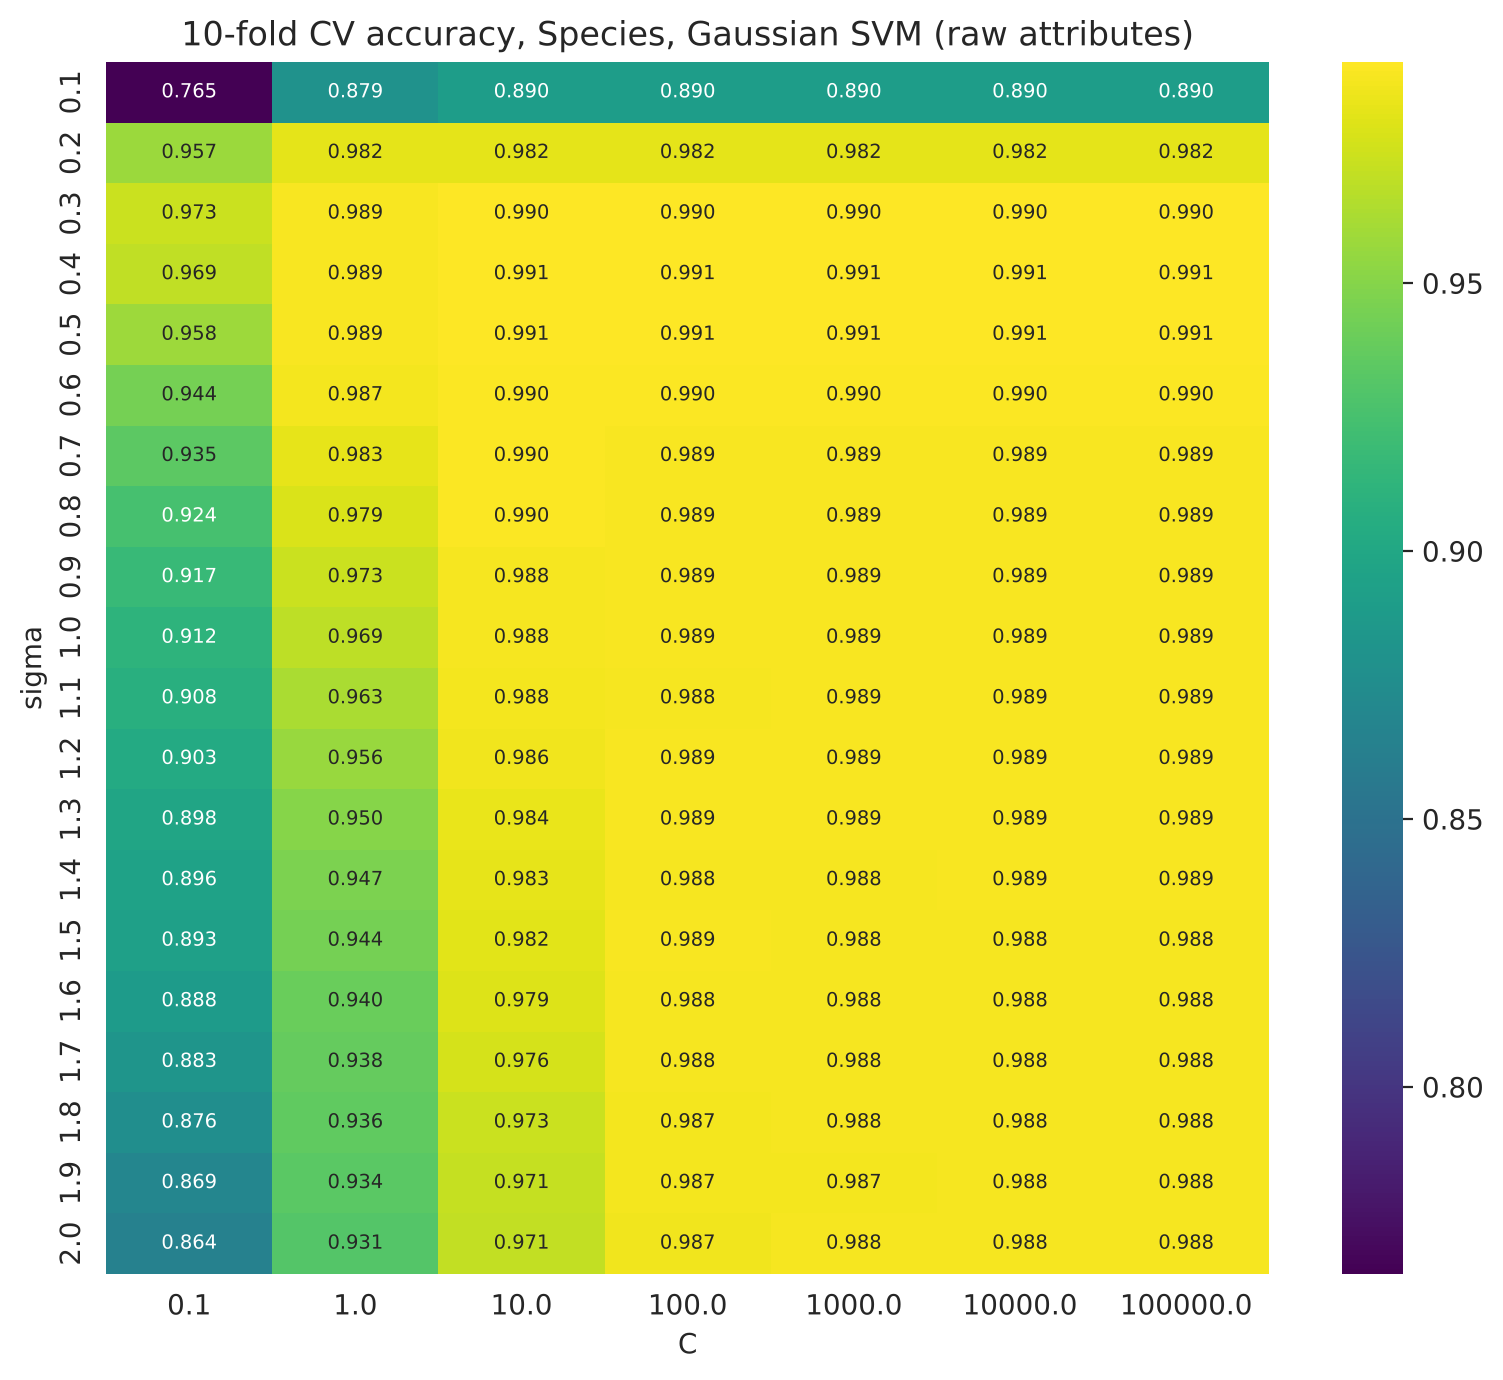

In [9]:
# CV accuracy surface for the Species classifier (raw attributes)
res = pd.DataFrame(rbf_raw["Species"].cv_results_)
res["C"] = res["param_svm__estimator__C"].astype(float)
res["sigma"] = np.round(np.sqrt(1 / (2 * res["param_svm__estimator__gamma"].astype(float))), 2)
heat = res.pivot(index="sigma", columns="C", values="mean_test_score")
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis", ax=ax, annot_kws={"size": 7})
ax.set_title("10-fold CV accuracy, Species, Gaussian SVM (raw attributes)")
plt.tight_layout(); plt.show()

**Results and discussion (Gaussian SVMs).**

| Attributes | Label | Best $C$ | Best $\sigma$ | CV accuracy | Test accuracy |
|---|---|---|---|---|---|
| Raw | Family | 100 | 0.4 | 0.9927 | 0.9949 |
| Raw | Genus | 10 | 0.4 | 0.9919 | 0.9917 |
| Raw | Species | 10 | 0.4 | 0.9913 | 0.9907 |
| Standardized | Family | 100 | 3.0 | 0.9921 | 0.9940 |
| Standardized | Genus | 10 | 3.0 | 0.9919 | 0.9880 |
| Standardized | Species | 10 | 3.5 | 0.9911 | 0.9880 |

| Attributes | Exact match (test) | Hamming loss (test) | Hamming score (test) |
|---|---|---|---|
| Raw | 0.9893 | 0.0076 | 0.9924 |
| Standardized | 0.9866 | 0.0100 | 0.9900 |

- The selected parameters lie inside the grid (not on its edges), so the grid ranges were wide enough. The CV accuracy surface for Species is flat over a broad region of moderate $C$ and $\sigma$, so the exact choice is not critical.
- The Gaussian SVMs are very accurate: on the test set about **98.9% of the frog calls get all three labels right**, and fewer than 1% of the individual labels are wrong. CV accuracy and test accuracy agree closely, so the current CV and test results show no clear generalization gap, even though the training accuracy is (almost) 100%.
- Raw and standardized attributes give practically the same CV accuracy; on the test set the raw attributes are slightly better (16 more correct labels out of 6,477: 49 vs. 65 wrong labels). The MFCCs are already scaled to $[-1, 1]$, so standardization is not needed; it also gives the same weight to low-variance coefficients such as `MFCCs_ 1` (standard deviation 0.07), which may add a little noise to the kernel distances. Since the selected $\sigma$ scales with the feature scale (0.4 raw vs. about 3 standardized), both versions end up with a similar kernel.

### iii. $L_1$-penalized SVMs

Following the convention in the footnote, the $L_1$-penalized SVM uses a **linear kernel**: `LinearSVC(penalty="l1", loss="squared_hinge", dual=False)`, which minimizes $\|\mathbf w\|_1 + C\sum_i \max(0, 1 - y_i\mathbf w^\top\mathbf x_i)^2$ for each class, with the one-versus-rest scheme for the multi-class labels. The attributes are standardized (the scaler is part of the pipeline, so in CV it is fit on the training folds only). $C$ is chosen by 10-fold stratified CV from $C \in \{10^{-3}, 10^{-2.5}, \dots, 10^{3}\}$.

In [10]:
C_l1 = np.logspace(-3, 3, 13)

def fit_l1(use_smote):
    fitted, rows = {}, []
    for lab in LABELS:
        steps = [("scale", StandardScaler())]
        if use_smote:
            steps.append(("smote", SMOTE(random_state=SEED)))
        steps.append(("svm", LinearSVC(penalty="l1", loss="squared_hinge", dual=False,
                                       max_iter=20000, random_state=SEED)))
        gs = GridSearchCV(ImbPipeline(steps), {"svm__C": C_l1}, cv=skf, scoring="accuracy", n_jobs=-1)
        gs.fit(X_train, Y_train[lab])
        coef = gs.best_estimator_.named_steps["svm"].coef_
        rows.append({"label": lab, "best C": gs.best_params_["svm__C"], "CV accuracy": gs.best_score_,
                     "test accuracy": gs.score(X_test, Y_test[lab]),
                     "zero coefficients": f"{(coef == 0).sum()} of {coef.size}"})
        fitted[lab] = gs
    return fitted, pd.DataFrame(rows).set_index("label")

l1_svm, l1_tab = fit_l1(use_smote=False)
print("L1-penalized linear SVM (standardized) — selected C (10-fold CV):")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(l1_tab)
report(l1_svm, "(iii) L1 linear SVM")

/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


L1-penalized linear SVM (standardized) — selected C (10-fold CV):


,best C,CV accuracy,test accuracy,zero coefficients
label,,,,
Family,10.0000,0.9412,0.9282,0 of 88
Genus,316.2278,0.9517,0.9416,0 of 176
Species,10.0000,0.9607,0.9592,0 of 220


,exact match,avg Hamming distance,Hamming loss,Hamming score,Hamming score (set-based),accuracy Family,accuracy Genus,accuracy Species
train,0.9251,0.1356,0.0452,0.9548,0.9463,0.9430,0.9567,0.9647
test,0.9125,0.1709,0.0570,0.9430,0.9342,0.9282,0.9416,0.9592


Wrong test labels: 369 of 6477


**Results and discussion ($L_1$-penalized linear SVMs).**

| Label | Best $C$ | CV accuracy | Test accuracy |
|---|---|---|---|
| Family | 10 | 0.9412 | 0.9282 |
| Genus | 316 | 0.9517 | 0.9416 |
| Species | 10 | 0.9607 | 0.9592 |

Test set: **exact match 0.9125, Hamming loss 0.0570, Hamming score 0.9430.**

- The linear models are clearly worse than the Gaussian-kernel SVMs (exact match 0.913 vs. 0.989; Hamming loss about 7 times larger). This indicates that a nonlinear decision boundary suits this problem much better. (The comparison by itself does not prove that the classes are not linearly separable; it only shows that the regularized linear SVMs selected by CV generalize much worse.)
- CV chose fairly large values of $C$ (weak regularization). At these values **no coefficient is exactly zero**, so at the selected $C$ the lasso penalty does not remove any MFCC, and stronger penalties (smaller $C$) did not improve the CV accuracy. This shows that CV preferred weak regularization; it does not prove that every MFCC is useful.
- The weakest label is Family, even though it has the fewest classes. A single linear boundary has to separate families that contain several acoustically different genera and species, and the smallest family, `Bufonidae` (68 instances), is **never predicted** (test recall 0 of 27; see the table in part iv). This is a direct effect of the class imbalance.

### iv. $L_1$-penalized SVMs with SMOTE

The classes are very imbalanced (for example, `Bufonidae` / `Rhinella` / `Rhinellagranulosa` has only 68 instances out of 7,195). To remedy this, **SMOTE** is added to the pipeline: after standardization, synthetic examples are generated for every minority class until all classes of that label have as many training examples as the largest class. SMOTE is applied **only to the training folds inside cross-validation** (and only to the training set for the final model); validation folds and the test set are never oversampled. $C$ is again chosen by 10-fold CV from the same grid.

In [11]:
l1_smote, l1s_tab = fit_l1(use_smote=True)
print("L1-penalized linear SVM + SMOTE (standardized) — selected C (10-fold CV):")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(l1s_tab)
report(l1_smote, "(iv) L1 linear SVM + SMOTE")

L1-penalized linear SVM + SMOTE (standardized) — selected C (10-fold CV):


,best C,CV accuracy,test accuracy,zero coefficients
label,,,,
Family,3.1623,0.9232,0.9092,2 of 88
Genus,1.0000,0.9128,0.9023,1 of 176
Species,3.1623,0.9581,0.9579,0 of 220


,exact match,avg Hamming distance,Hamming loss,Hamming score,Hamming score (set-based),accuracy Family,accuracy Genus,accuracy Species
train,0.8697,0.1914,0.0638,0.9362,0.9180,0.9241,0.9204,0.9641
test,0.8536,0.2307,0.0769,0.9231,0.9040,0.9092,0.9023,0.9579


Wrong test labels: 498 of 6477


In [12]:
# Per-class recall on the test set: does SMOTE help the small classes?
rows = []
for lab in LABELS:
    classes = sorted(Y_train[lab].unique())
    r_plain = recall_score(Y_test[lab], l1_svm[lab].predict(X_test), labels=classes, average=None, zero_division=0)
    r_smote = recall_score(Y_test[lab], l1_smote[lab].predict(X_test), labels=classes, average=None, zero_division=0)
    for c, a, b in zip(classes, r_plain, r_smote):
        rows.append({"label": lab, "class": c, "test count": int((Y_test[lab] == c).sum()),
                     "recall L1 SVM": a, "recall L1 SVM + SMOTE": b})
recall_cmp = pd.DataFrame(rows).set_index(["label", "class"])
with pd.option_context("display.float_format", "{:.3f}".format):
    display(recall_cmp)

test count  recall L1 SVM  recall L1 SVM + SMOTE
label   class                                                                   
Family  Bufonidae                       27          0.000                  0.889
        Dendrobatidae                  162          0.895                  0.975
        Hylidae                        623          0.904                  0.867
        Leptodactylidae               1347          0.962                  0.921
Genus   Adenomera                     1251          0.978                  0.890
        Ameerega                       162          0.932                  0.957
        Dendropsophus                   84          0.714                  0.893
        Hypsiboas                      468          0.970                  0.912
        Leptodactylus                   96          0.906                  0.896
        Osteocephalus                   34          0.500                  0.882
        Rhinella                        27          0.259                  0.926
        Scinax                          37          0.892                  0.973
Species AdenomeraAndre                 220          0.914                  0.877
        AdenomeraHylaedactylus        1031          0.999                  0.995
        Ameeregatrivittata             162          0.944                  0.944
        HylaMinuta                      84          0.774                  0.893
        HypsiboasCinerascens           135          0.963                  0.963
        HypsiboasCordobae              333          0.976                  0.943
        LeptodactylusFuscus             96          0.896                  0.906
        OsteocephalusOophagus           34          0.647                  0.882
        Rhinellagranulosa               27          0.889                  0.926
        ScinaxRuber                     37          0.946                  0.946

In [13]:
# Convergence check for the L1-penalized LinearSVC. GridSearchCV fits the models in parallel
# worker processes, so convergence warnings raised there are not shown in the notebook.
# Instead, every C in the grid is refit on the full training set (with and without SMOTE) and the
# number of solver iterations is compared with max_iter = 20000.
def n_iter_for(lab, C, use_smote):
    steps = [("scale", StandardScaler())] + ([("smote", SMOTE(random_state=SEED))] if use_smote else [])
    steps.append(("svm", LinearSVC(penalty="l1", loss="squared_hinge", dual=False, C=C,
                                   max_iter=20000, random_state=SEED)))
    return ImbPipeline(steps).fit(X_train, Y_train[lab]).named_steps["svm"].n_iter_

jobs = [(lab, C, sm) for sm in (False, True) for lab in LABELS for C in C_l1]
iters = Parallel(n_jobs=-1)(delayed(n_iter_for)(*j) for j in jobs)
conv = pd.DataFrame([{"SMOTE": sm, "label": lab, "C": C, "iterations": it} for (lab, C, sm), it in zip(jobs, iters)])
print(f"Maximum number of iterations over all fits: {conv['iterations'].max()} (max_iter = 20000)")
print(f"Fits that reached max_iter (did not converge): {(conv['iterations'] >= 20000).sum()} of {len(conv)}")
display(conv.pivot_table(index=["SMOTE", "label"], columns="C", values="iterations").round(0).astype(int))

Maximum number of iterations over all fits: 3967 (max_iter = 20000)
Fits that reached max_iter (did not converge): 0 of 78


C              0.001000     0.003162     0.010000     0.031623     0.100000     0.316228     1.000000     3.162278     10.000000    \
SMOTE label                                                                                                                          
False Family           101          134          178          379          788          816         1667         1565         1612   
      Genus             41           83          200          464         1015         1555         2384         1698         1872   
      Species          141          203          150          713         1085         1520         1843         1693         1868   
True  Family           131          543          663         1288         1719         1589         1710         1441         1447   
      Genus            197          404          878          920         1635         1833         1890         2147         2534   
      Species          437          544         1531         1920         3144         1902         1980         1998         2034   

C              31.622777    100.000000   316.227766   1000.000000  
SMOTE label                                                        
False Family          1070         1070         1070         1070  
      Genus           1559         1559         1559         1559  
      Species         1559         1511         1511         1511  
True  Family          1447         1447         1447         1447  
      Genus           2790         3414         3414         3414  
      Species         3967         3967         3967         3967

**Convergence of the $L_1$ SVMs.** During the 10-fold cross-validation in part (iii), liblinear printed 7 `ConvergenceWarning`s (visible in the output of that cell): 7 of the $13 \times 10 \times 3 = 390$ CV fits stopped at `max_iter = 20000`. The CV fits in part (iv) produced no warnings. The table above shows that every refit on the full training set converged, with at most 3,967 iterations, including the selected models. The few non-converged CV fits can only slightly change the CV accuracy of the affected $(C, \text{fold})$ combinations, and the final models used for the test results are fully converged.

In [14]:
summary_df = pd.DataFrame(summary).T
with pd.option_context("display.float_format", "{:.4f}".format):
    display(summary_df)

,exact match,avg Hamming distance,Hamming loss,Hamming score,Hamming score (set-based),accuracy Family,accuracy Genus,accuracy Species
"(ii) Gaussian SVM, raw",0.9893,0.0227,0.0076,0.9924,0.9915,0.9949,0.9917,0.9907
"(ii) Gaussian SVM, standardized",0.9866,0.0301,0.0100,0.9900,0.9888,0.9940,0.9880,0.9880
(iii) L1 linear SVM,0.9125,0.1709,0.0570,0.9430,0.9342,0.9282,0.9416,0.9592
(iv) L1 linear SVM + SMOTE,0.8536,0.2307,0.0769,0.9231,0.9040,0.9092,0.9023,0.9579


**Results and conclusions.**

With SMOTE, CV selected $C = 3.16$ (Family), $1$ (Genus) and $3.16$ (Species). Test set: **exact match 0.8536, Hamming loss 0.0769, Hamming score 0.9231**, compared with 0.9125 / 0.0570 / 0.9430 without SMOTE.

- **SMOTE helps the small classes and costs accuracy on the large ones.** Test recall rises sharply for the minority classes: `Bufonidae` 0.00 → 0.89, `Rhinella` 0.26 → 0.93, `Osteocephalus` 0.50 → 0.88, `Dendropsophus` 0.71 → 0.89, `OsteocephalusOophagus` 0.65 → 0.88. Recall drops for the large classes (`Adenomera` 0.98 → 0.89, `Leptodactylidae` 0.96 → 0.92). Macro recall therefore improves for every label (Family 0.69 → 0.91, Genus 0.77 → 0.92, Species 0.89 → 0.93; see part vi).
- **Exact match and Hamming loss get worse with SMOTE**, because these metrics are dominated by the large classes (`AdenomeraHylaedactylus` alone is almost half of the data). Which version is "better" depends on the goal: if the rare species matter as much as the common ones, the SMOTE version is preferable; if overall accuracy matters, it is not.
- **Overall conclusion.** The **Gaussian-kernel SVM with raw attributes is the best classifier** in this problem by every metric (exact match 0.989, Hamming loss 0.008, macro recall 0.96–0.98, macro AUC ≥ 0.997). It also handles the minority classes well without any rebalancing (e.g. 25 of 27 test `Bufonidae` calls are correct). For the linear models, the lack of flexibility appears to be the main limitation, and SMOTE mostly moves errors from the small classes to the large ones. Using a nonlinear kernel matters much more here than correcting the class imbalance.
- **A weakness of binary relevance.** The labels are trained independently, so their predictions can contradict each other. For example, the $L_1$ SVM for Family never predicts `Bufonidae`, while the Species classifier correctly recognizes 89% of the `Rhinellagranulosa` calls, which are exactly the same frogs (`Rhinellagranulosa` is the only species in `Bufonidae`). Methods that use the dependence between labels, such as the classifier chain in part v, address this.

### v. Extra practice: classifier chain

**Classifier chain (Read et al., 2009).** Binary relevance trains each label independently and ignores dependencies between labels. A classifier chain orders the labels and trains them in sequence; the classifier for label $j$ uses the original features **plus the labels $1, \dots, j-1$** as extra inputs. During training the true values of the earlier labels are used; at prediction time the chain feeds its own predictions forward. Here the natural order is Family → Genus → Species (the taxonomy is hierarchical, so knowing the family narrows down the genus and species). The earlier labels are one-hot encoded and appended to the standardized MFCCs. Each link is a Gaussian SVM (one-versus-rest) with the parameters selected in part (ii) for standardized attributes.

In [15]:
class FrogChain:
    def __init__(self, params):
        self.params = params   # {label: (C, gamma)}

    def _augment(self, Xs, Yprev, j):
        if j == 0:
            return Xs
        oh = [label_binarize(Yprev[:, k], classes=self.classes_[LABELS[k]]) for k in range(j)]
        oh = [o if o.shape[1] > 1 else np.hstack([1 - o, o]) for o in oh]
        return np.hstack([Xs] + oh)

    def fit(self, X, Y):
        self.scaler = StandardScaler().fit(X); Xs = self.scaler.transform(X)
        Yv = np.asarray(Y, dtype=object)
        self.classes_ = {lab: sorted(Y[lab].unique()) for lab in LABELS}
        self.models = []
        for j, lab in enumerate(LABELS):
            C, g = self.params[lab]
            self.models.append(OneVsRestClassifier(SVC(kernel="rbf", C=C, gamma=g)).fit(self._augment(Xs, Yv, j), Yv[:, j]))
        return self

    def predict(self, X):
        return self.predict_with_scores(X)[0]

    def predict_with_scores(self, X):
        # predicted labels, and for each label the decision values of its link (given the earlier predictions)
        Xs = self.scaler.transform(X)
        P = np.empty((len(X), len(LABELS)), dtype=object); S = {}
        for j, lab in enumerate(LABELS):
            Xa = self._augment(Xs, P, j)
            P[:, j] = self.models[j].predict(Xa)
            S[lab] = (self.models[j].classes_, self.models[j].decision_function(Xa))
        return pd.DataFrame(P, columns=LABELS), S

params = {lab: (rbf_std[lab].best_params_["svm__estimator__C"], rbf_std[lab].best_params_["svm__estimator__gamma"])
          for lab in LABELS}
chain = FrogChain(params).fit(X_train, Y_train)
tr = multilabel_metrics(Y_train, chain.predict(X_train)); te = multilabel_metrics(Y_test, chain.predict(X_test))
summary["(v) Classifier chain (Gaussian SVM)"] = te
with pd.option_context("display.float_format", "{:.4f}".format):
    display(pd.DataFrame({"train": tr, "test": te}).T)

# Consistency check: how many test predictions are taxonomically impossible combinations?
valid = set(map(tuple, Y_all.drop_duplicates().values))
for name, P in [("binary relevance (ii, standardized)", predict_all(rbf_std, X_test)), ("classifier chain", chain.predict(X_test))]:
    bad = sum(tuple(r) not in valid for r in P.values)
    print(f"{name}: {bad} test predictions are not a valid (family, genus, species) combination")

,exact match,avg Hamming distance,Hamming loss,Hamming score,Hamming score (set-based),accuracy Family,accuracy Genus,accuracy Species
train,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
test,0.9889,0.0269,0.0090,0.9910,0.9903,0.9940,0.9893,0.9898


binary relevance (ii, standardized): 15 test predictions are not a valid (family, genus, species) combination
classifier chain: 5 test predictions are not a valid (family, genus, species) combination


**Results.** The classifier chain (Family → Genus → Species, Gaussian SVMs with the standardized-attribute parameters from part ii) reaches a test **exact match of 0.9889 and Hamming loss of 0.0090**. This is slightly better than binary relevance with the same base models and parameters (0.9866 / 0.0100). It also produces fewer taxonomically impossible predictions (5 vs. 15 test instances whose predicted family, genus and species do not form a valid combination), because the later classifiers can use the earlier predicted labels. The improvement is small, since the per-label Gaussian SVMs are already very accurate, and it is about the same as binary relevance with raw attributes (exact match 0.9893).

### vi. Extra practice: confusion matrices, precision, recall, ROC and AUC for multi-label classification

For a multi-label problem these quantities are computed **per label** and then combined:

- **Confusion matrix:** one matrix per label (here a $4\times4$, an $8\times8$ and a $10\times10$ matrix). In the binary-indicator view one can also build a $2\times2$ matrix for each of the 22 label values (scikit-learn's `multilabel_confusion_matrix`).
- **Precision and recall:** for each class $c$ of a label, $\text{precision}_c = TP_c/(TP_c+FP_c)$ and $\text{recall}_c = TP_c/(TP_c+FN_c)$. They are combined by **macro-averaging** (unweighted mean over classes, so small classes count as much as large ones) or **micro-averaging** (pool all $TP$, $FP$, $FN$ first; for single-label multi-class problems micro precision = micro recall = accuracy). Instance-based versions (Sorower) are $\frac1N\sum_i|Y_i\cap Z_i|/|Z_i|$ and $\frac1N\sum_i|Y_i\cap Z_i|/|Y_i|$; here $|Y_i|=|Z_i|=3$, so both equal the Hamming score.
- **ROC and AUC:** ROC curves need scores, not just labels. For each label, each class gets a one-versus-rest ROC curve from the SVM decision values; AUCs are macro-averaged over classes (and a micro-averaged ROC pools all class/instance pairs).

Below, all of these are computed on the test set for **all five models** (the four binary-relevance models from parts ii–iv and the classifier chain from part v). For the chain, the scores of each link are computed given the labels predicted earlier in the chain.

In [16]:
def outputs(name):
    # For each label: (classes, predicted labels, decision values) on the test set
    if name == "(v) Classifier chain":
        P, S = chain.predict_with_scores(X_test)
        return {lab: (S[lab][0], P[lab].values, S[lab][1]) for lab in LABELS}
    models = model_sets[name]
    return {lab: (models[lab].classes_, models[lab].predict(X_test), models[lab].decision_function(X_test))
            for lab in LABELS}

model_sets = {"(ii) Gaussian SVM, raw": rbf_raw, "(ii) Gaussian SVM, standardized": rbf_std,
              "(iii) L1 linear SVM": l1_svm, "(iv) L1 linear SVM + SMOTE": l1_smote}
all_models = list(model_sets) + ["(v) Classifier chain"]
OUT = {name: outputs(name) for name in all_models}

rows = []
for name in all_models:
    for lab in LABELS:
        classes, yp, s = OUT[name][lab]
        yb = label_binarize(Y_test[lab], classes=classes)
        rows.append({"model": name, "label": lab,
                     "macro precision": precision_score(Y_test[lab], yp, average="macro", zero_division=0),
                     "macro recall": recall_score(Y_test[lab], yp, average="macro", zero_division=0),
                     "micro precision = recall": precision_score(Y_test[lab], yp, average="micro"),
                     "macro AUC (OvR)": roc_auc_score(yb, s, average="macro"),
                     "micro AUC": roc_auc_score(yb, s, average="micro")})
perlabel = pd.DataFrame(rows).set_index(["model", "label"])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(perlabel)

macro precision  macro recall  micro precision = recall  macro AUC (OvR)  micro AUC
model                           label                                                                                       
(ii) Gaussian SVM, raw          Family            0.9947        0.9782                    0.9949           0.9996     0.9997
                                Genus             0.9874        0.9615                    0.9917           0.9973     0.9994
                                Species           0.9807        0.9681                    0.9907           0.9973     0.9990
(ii) Gaussian SVM, standardized Family            0.9943        0.9788                    0.9940           0.9986     0.9996
                                Genus             0.9826        0.9497                    0.9880           0.9967     0.9992
                                Species           0.9765        0.9573                    0.9880           0.9969     0.9989
(iii) L1 linear SVM             Family            0.6756        0.6902                    0.9282           0.9768     0.9846
                                Genus             0.9237        0.7690                    0.9416           0.9856     0.9925
                                Species           0.9254        0.8948                    0.9592           0.9888     0.9944
(iv) L1 linear SVM + SMOTE      Family            0.7421        0.9131                    0.9092           0.9678     0.9763
                                Genus             0.7415        0.9162                    0.9023           0.9769     0.9832
                                Species           0.8857        0.9276                    0.9579           0.9839     0.9921
(v) Classifier chain            Family            0.9943        0.9788                    0.9940           0.9986     0.9996
                                Genus             0.9855        0.9571                    0.9893           0.9982     0.9993
                                Species           0.9842        0.9664                    0.9898           0.9983     0.9988

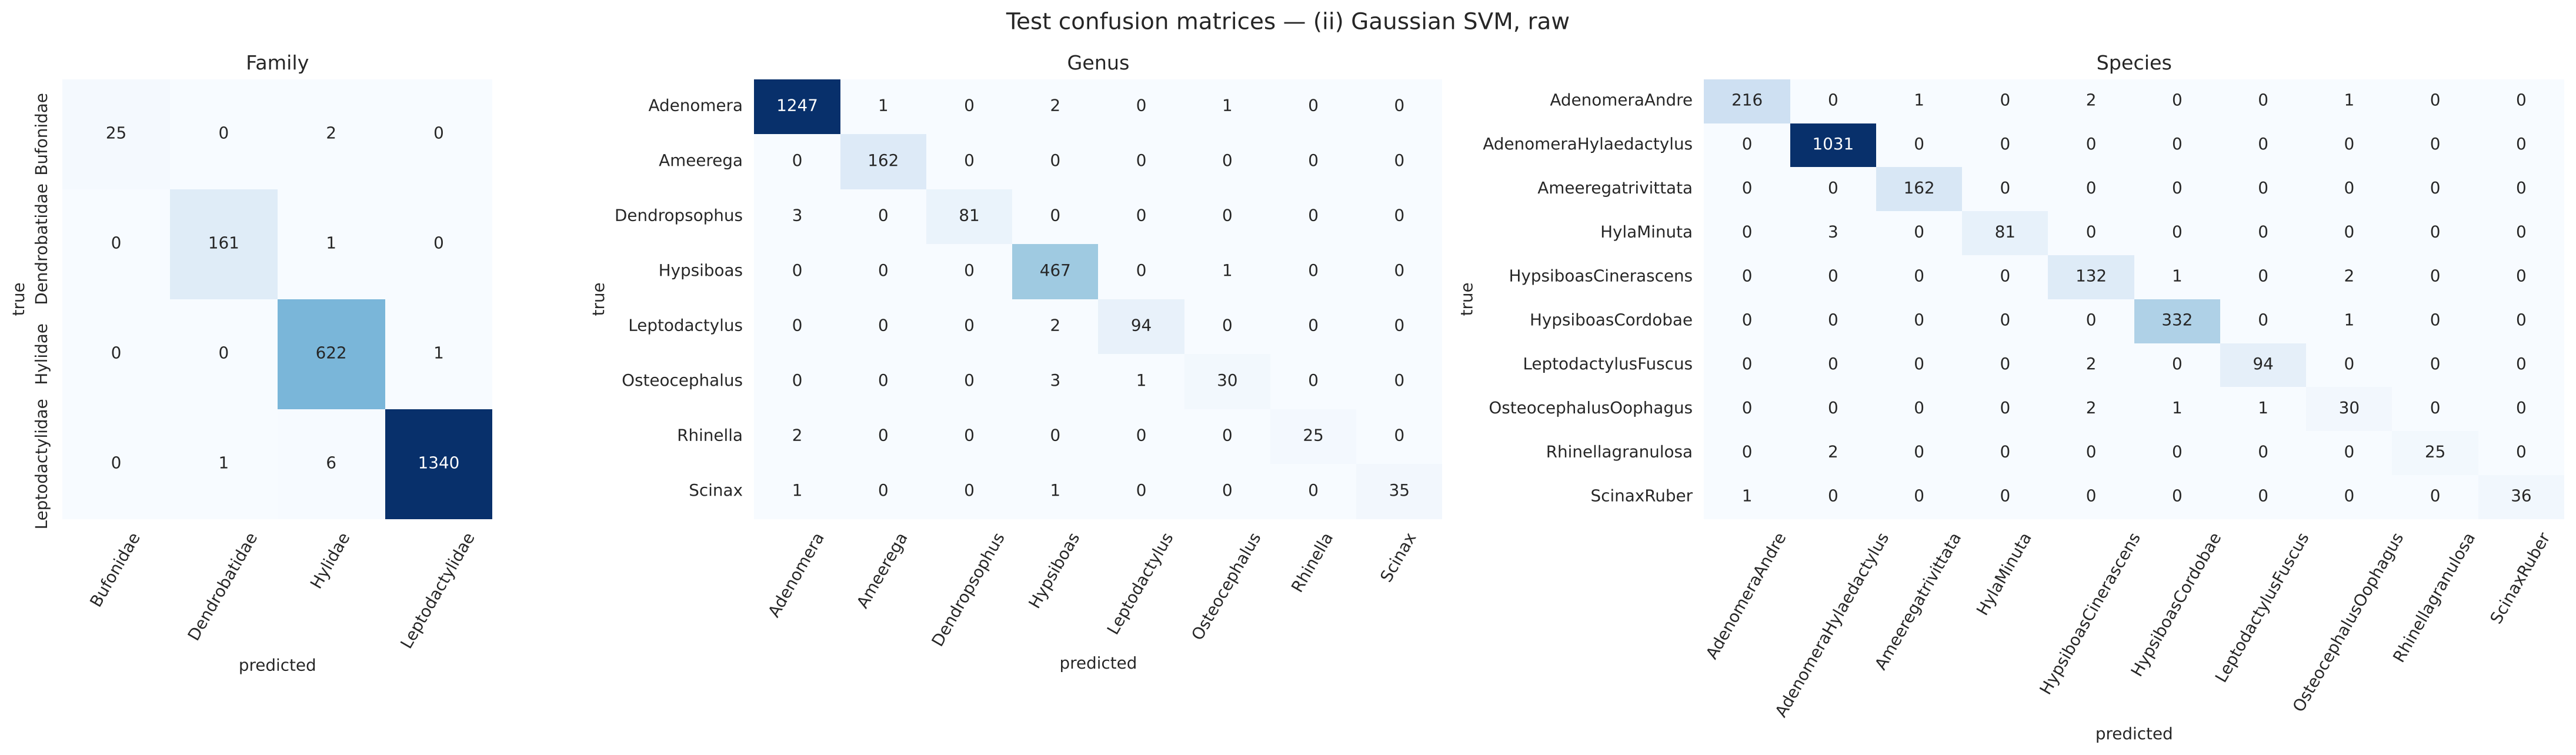

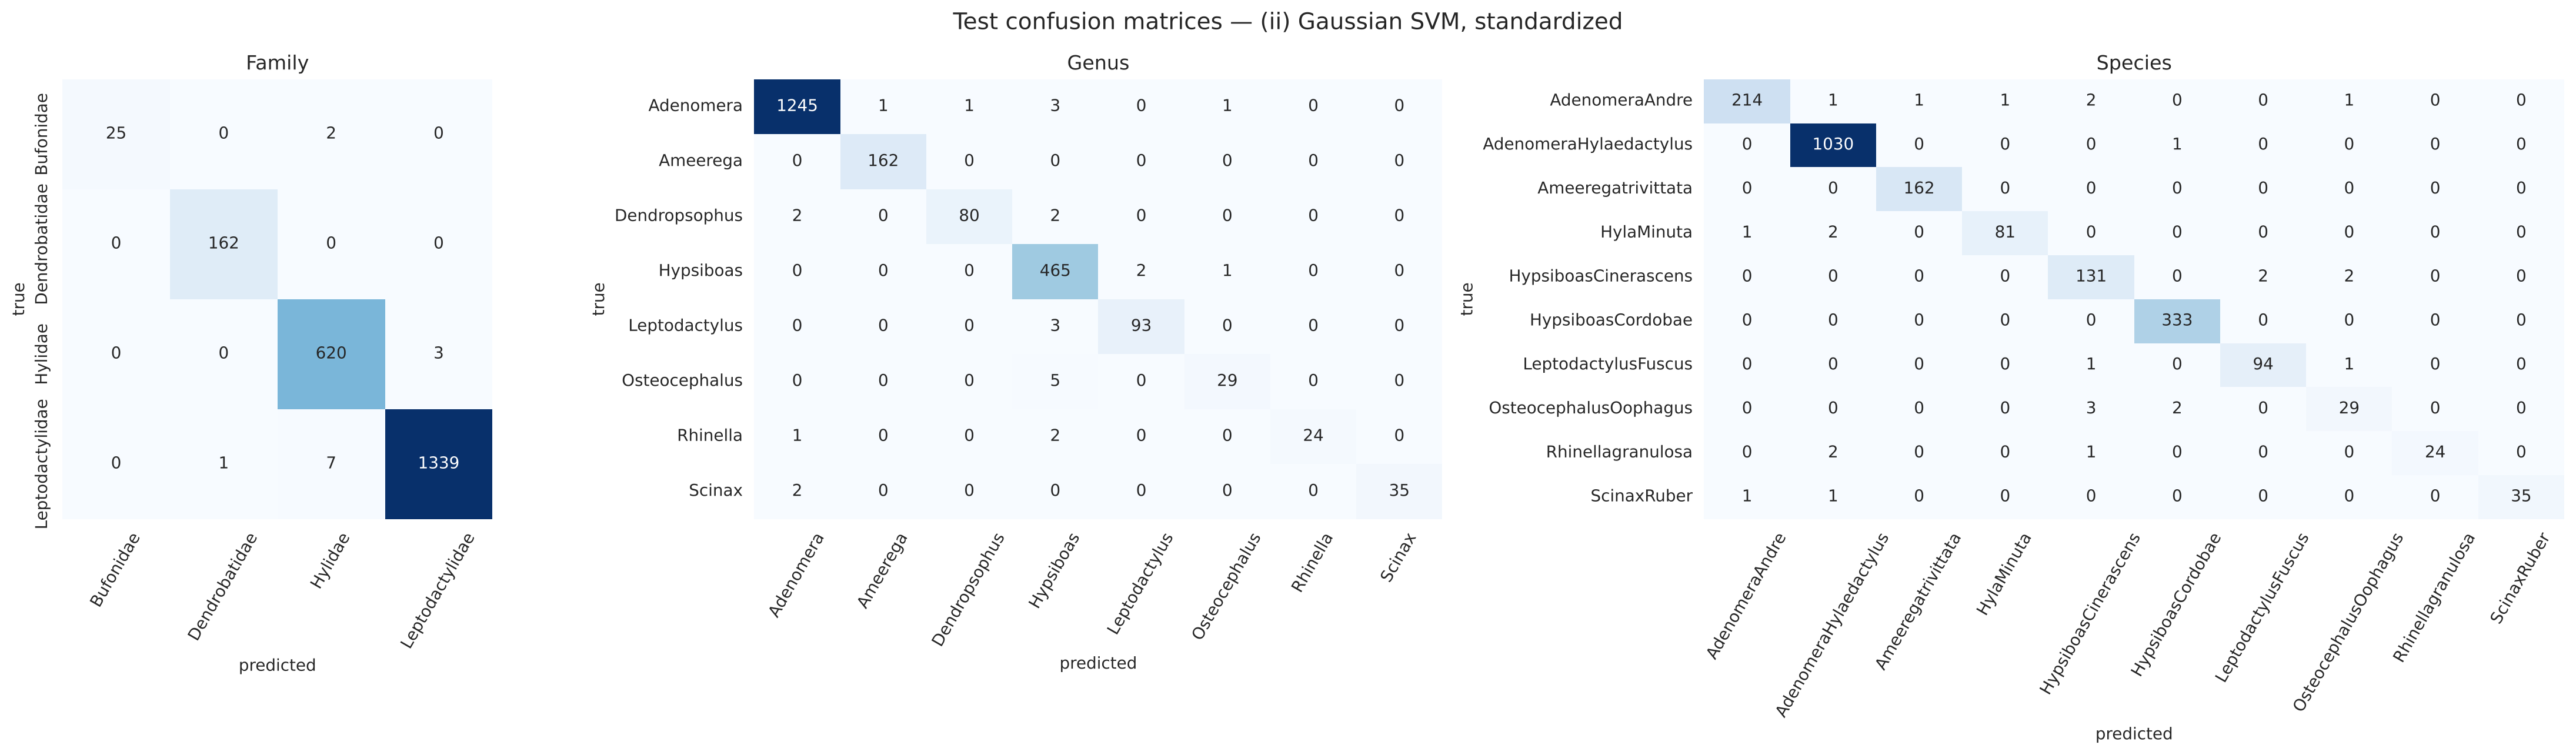

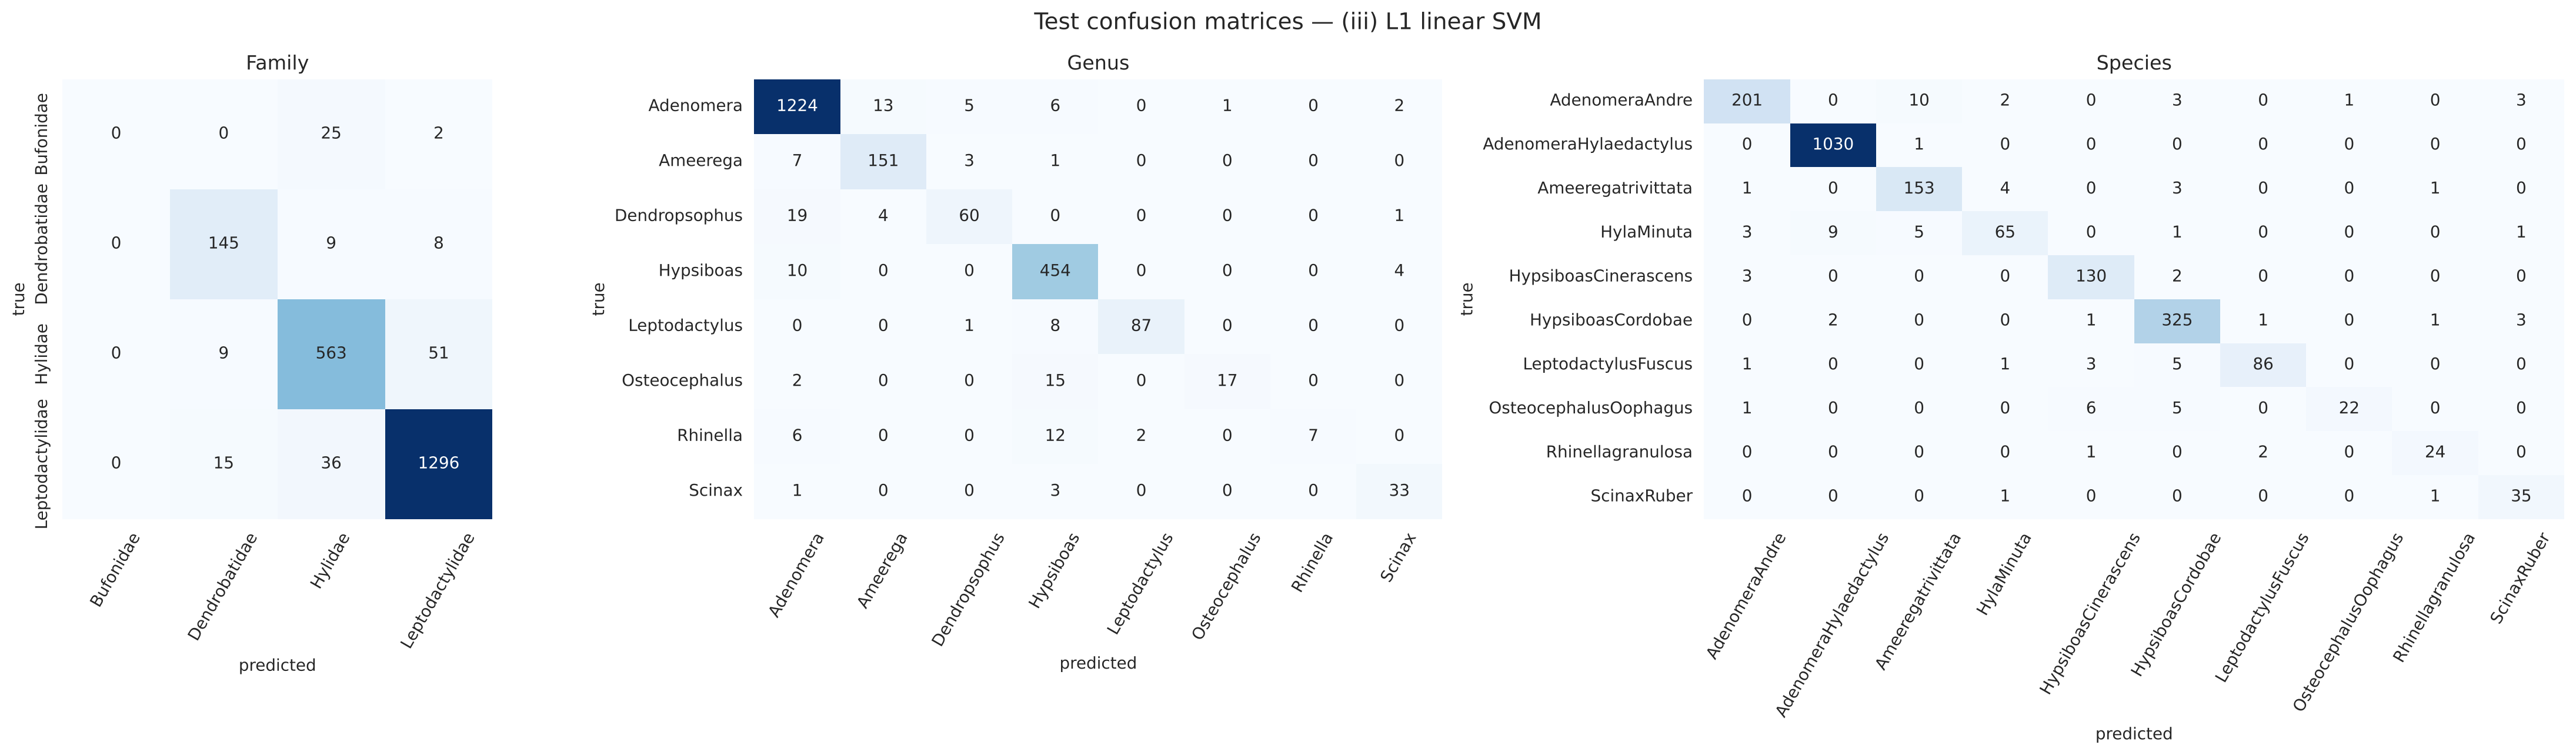

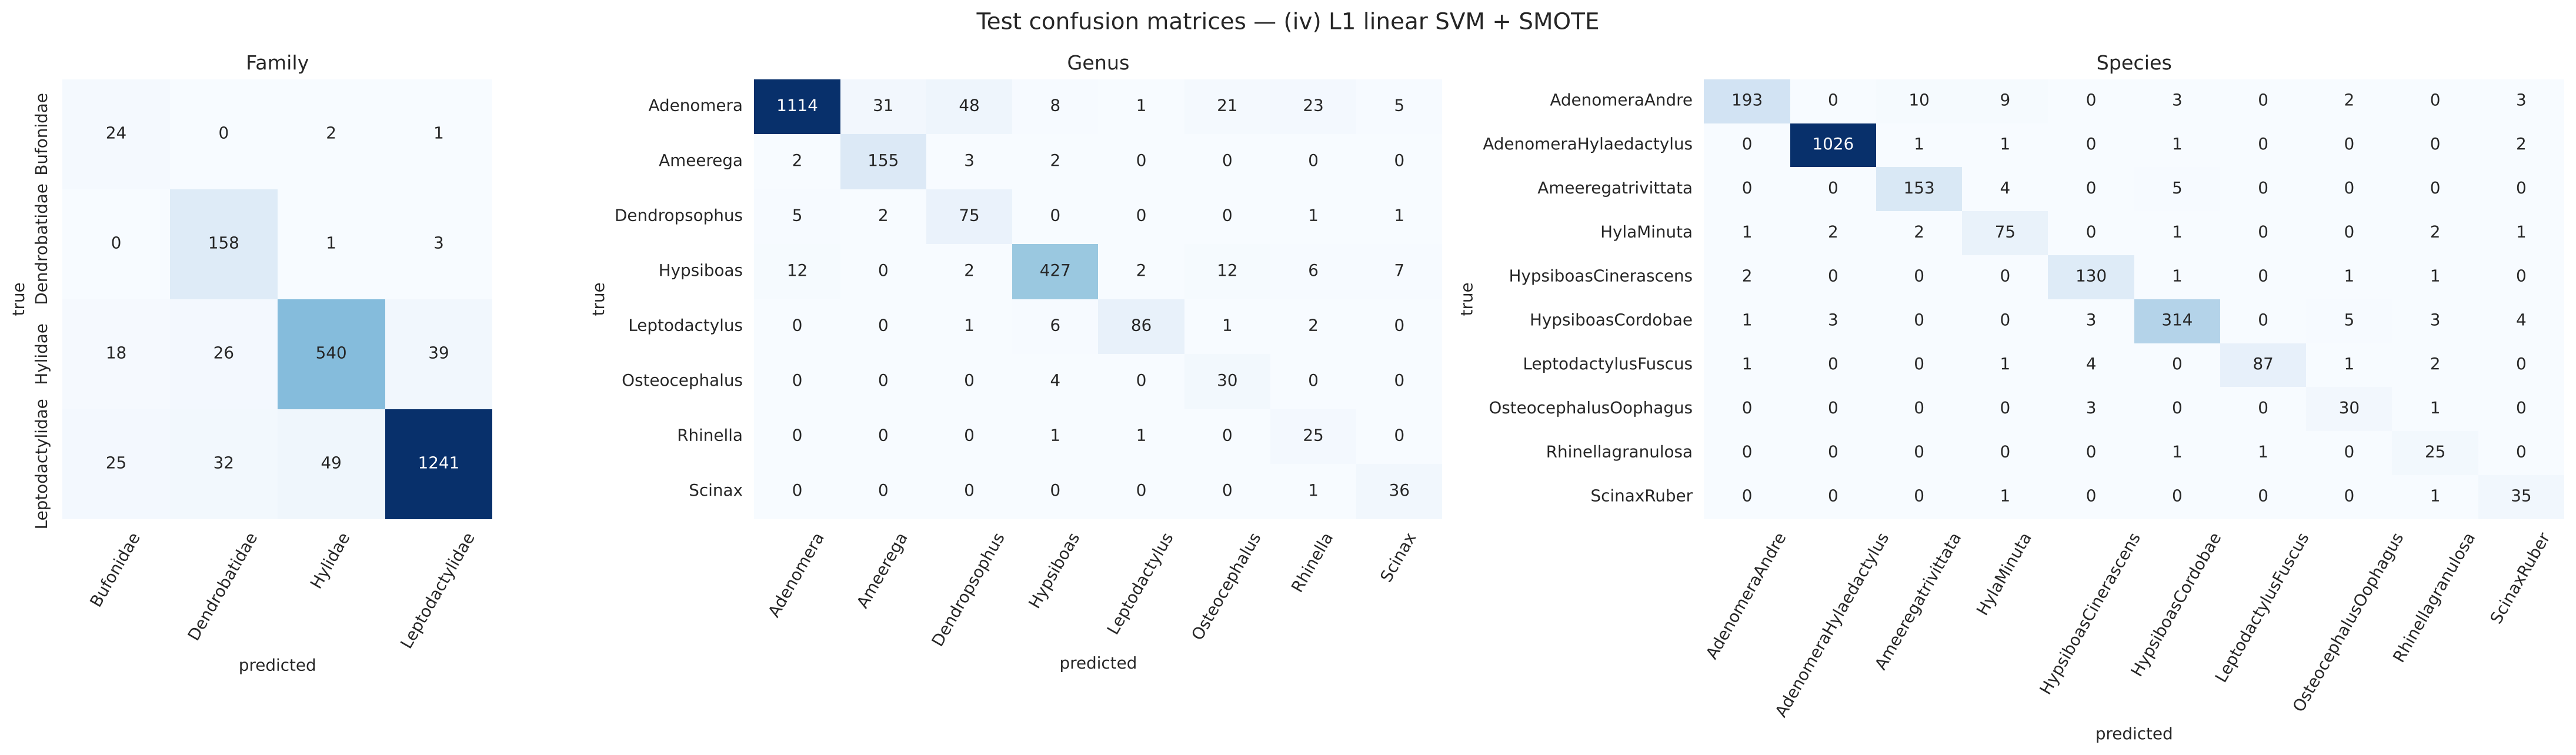

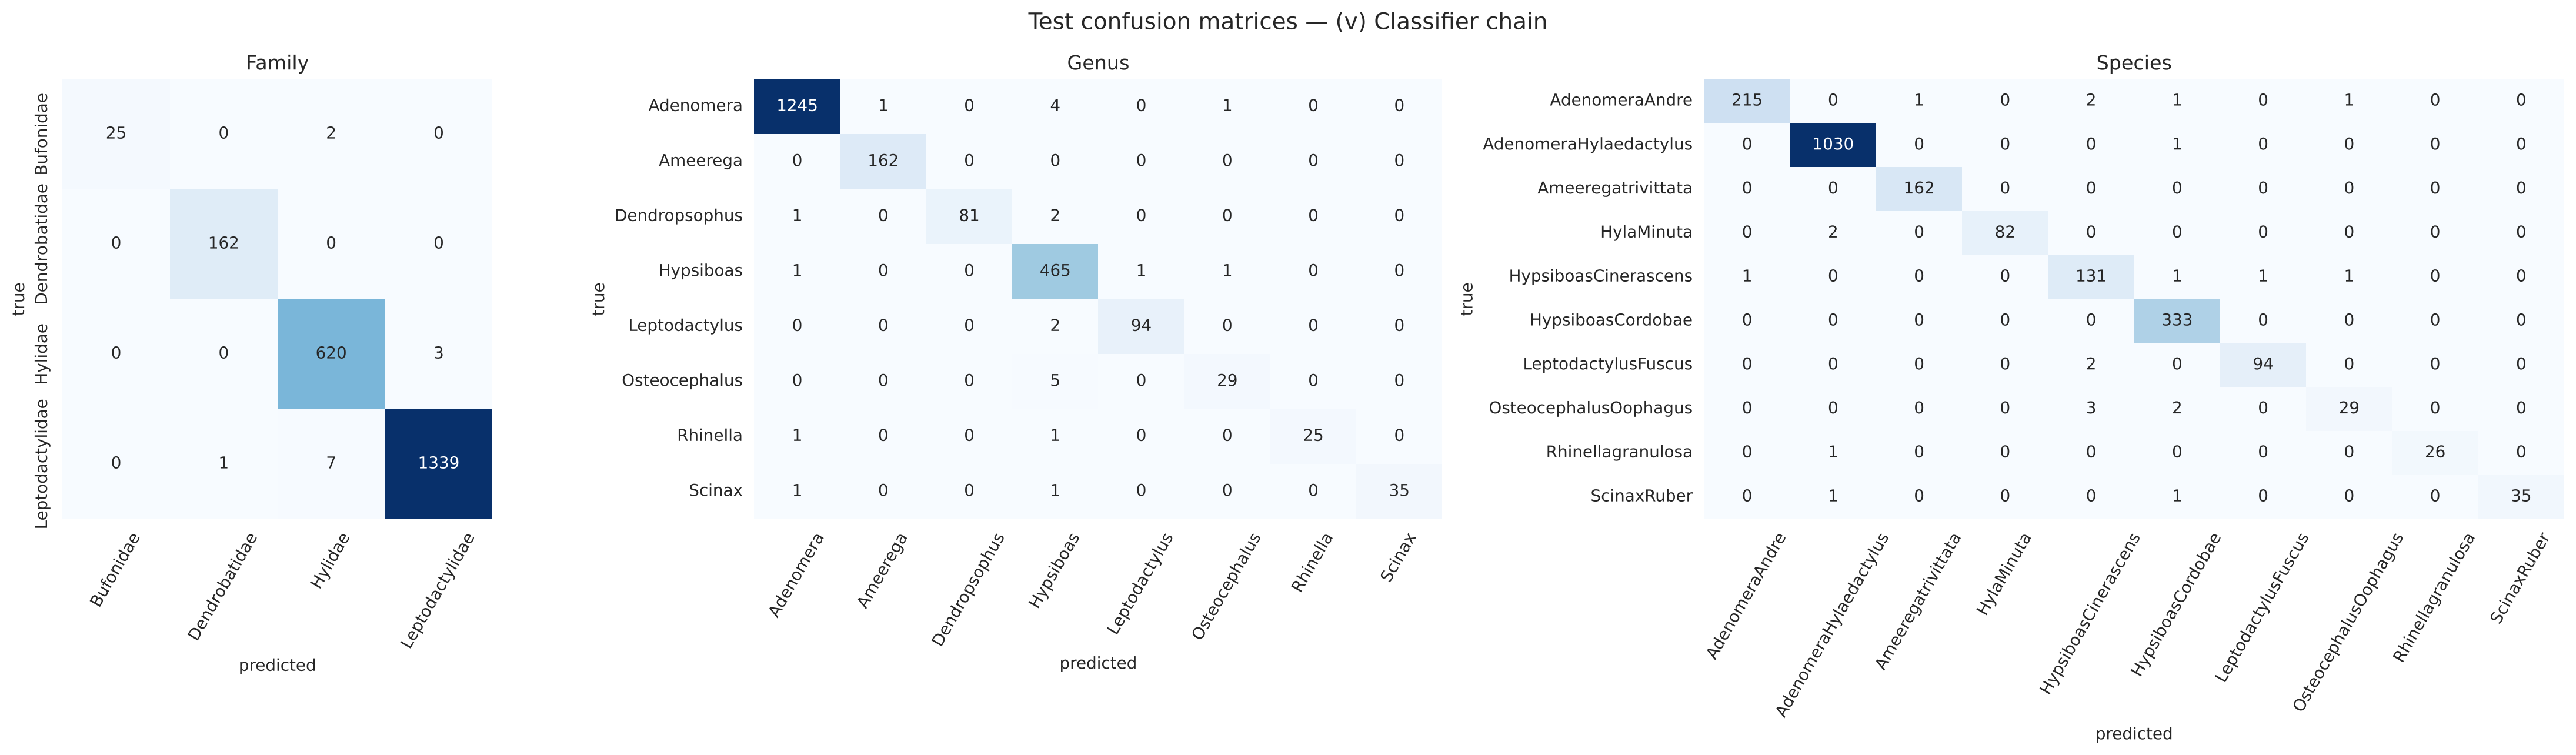

In [17]:
# Test-set confusion matrices for every model (rows = true class, columns = predicted class)
for name in all_models:
    fig, axes = plt.subplots(1, 3, figsize=(22, 6.5), gridspec_kw={"width_ratios": [1, 1.6, 2]})
    for ax, lab in zip(axes, LABELS):
        classes, yp, _ = OUT[name][lab]
        cm = confusion_matrix(Y_test[lab], yp, labels=classes)
        sns.heatmap(pd.DataFrame(cm, index=classes, columns=classes), annot=True, fmt="d", cmap="Blues",
                    cbar=False, ax=ax)
        ax.set_title(f"{lab}"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
        ax.tick_params(axis="x", rotation=60)
    fig.suptitle(f"Test confusion matrices — {name}", fontsize=14)
    plt.tight_layout(); plt.show()

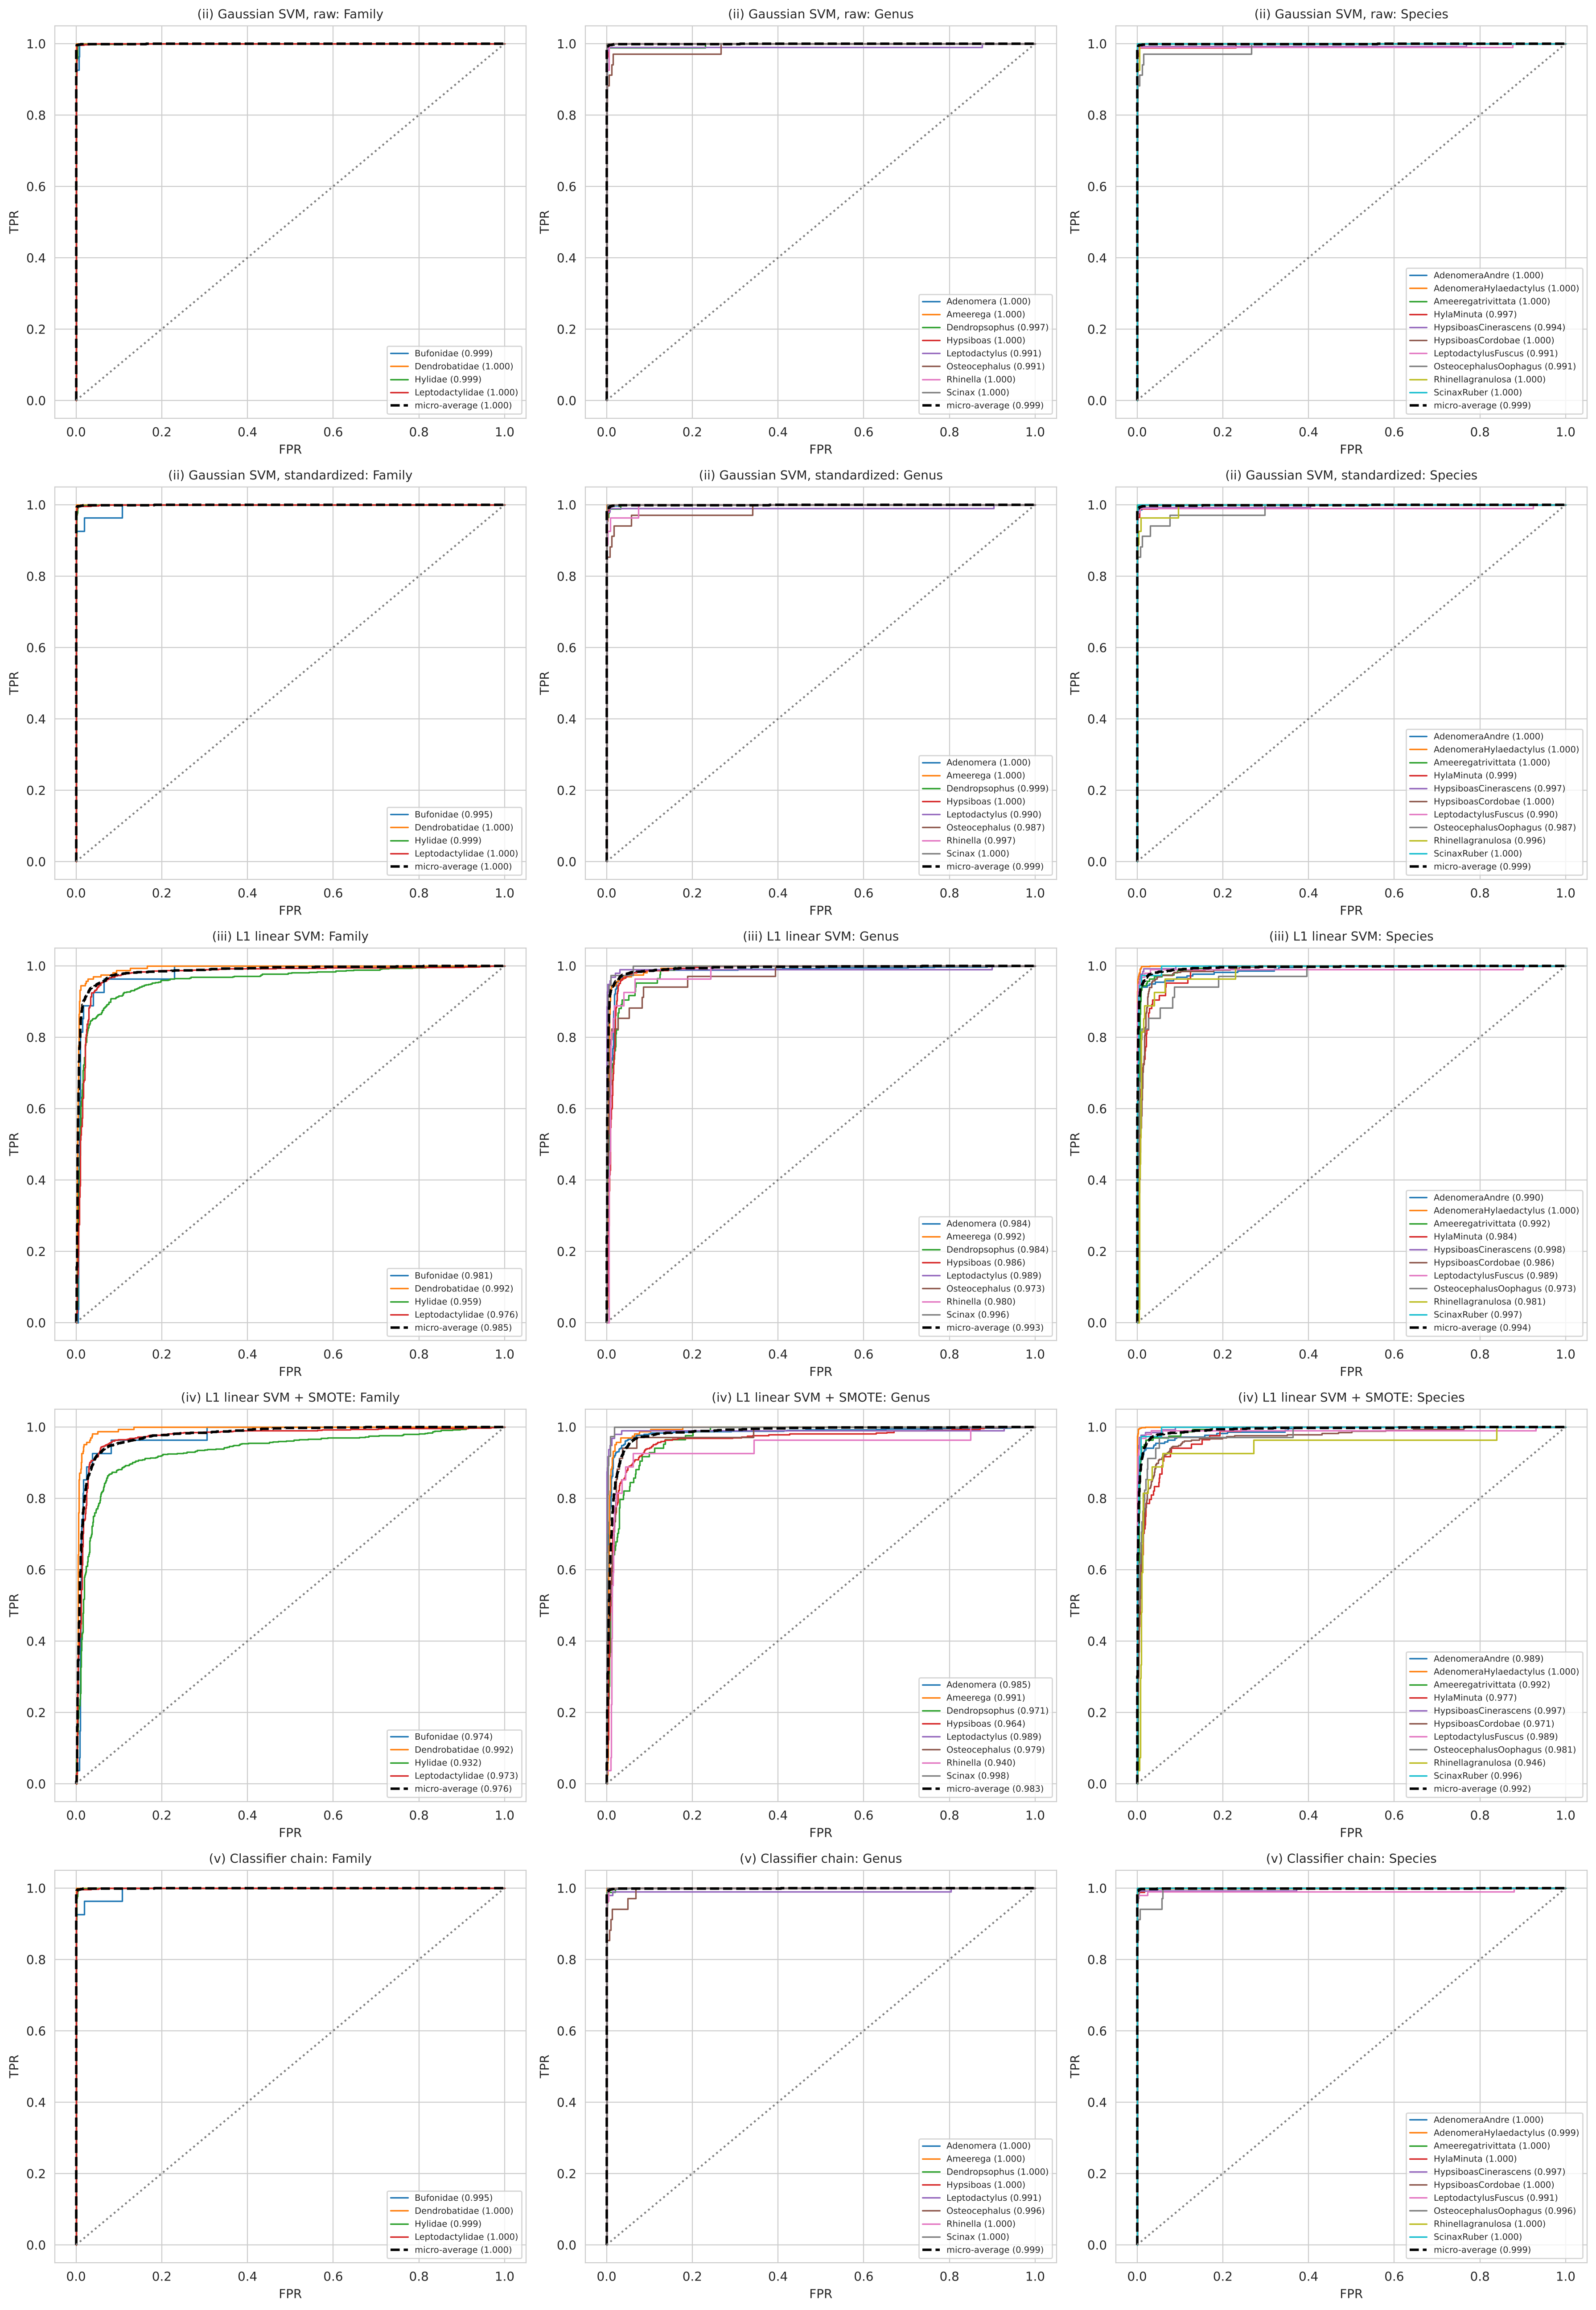

In [18]:
# One-vs-rest ROC curves per label (test set) for every model
fig, axes = plt.subplots(len(all_models), 3, figsize=(18, 5.2 * len(all_models)))
for row, name in enumerate(all_models):
    for ax, lab in zip(axes[row], LABELS):
        classes, _, s = OUT[name][lab]
        yb = label_binarize(Y_test[lab], classes=classes)
        for k, c in enumerate(classes):
            fpr, tpr, _ = roc_curve(yb[:, k], s[:, k])
            ax.plot(fpr, tpr, lw=1.2, label=f"{c} ({roc_auc_score(yb[:, k], s[:, k]):.3f})")
        fpr, tpr, _ = roc_curve(yb.ravel(), s.ravel())
        ax.plot(fpr, tpr, "k--", lw=2, label=f"micro-average ({roc_auc_score(yb, s, average='micro'):.3f})")
        ax.plot([0, 1], [0, 1], ":", color="gray")
        ax.set_title(f"{name}: {lab}", fontsize=10); ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

**Discussion.**

- **Gaussian SVMs:** macro precision 0.98–0.99, macro recall 0.95–0.98 and macro AUC ≥ 0.996 for all three labels (raw and standardized). The confusion matrices for the raw-attribute model show that the few errors are mostly calls assigned to a larger, related class (e.g. 6 `Leptodactylidae` calls predicted as `Hylidae`, 2 `Rhinella` calls predicted as `Adenomera`). The ROC curves are close to the top-left corner for every class.
- **$L_1$ linear SVMs:** micro precision/recall (= accuracy) is still above 0.92, but macro recall is much lower (Family 0.69, Genus 0.77), which reveals the poor performance on small classes that the accuracy hides. Family macro precision is only 0.68 because `Bufonidae` is never predicted (its precision is counted as 0).
- **Classifier chain:** macro precision 0.98–0.99, macro recall 0.96–0.98 and macro AUC ≥ 0.998, very close to the standardized Gaussian SVMs it is built from (its Family link is the same model, so the Family results are identical; Genus and Species macro recall are slightly higher, 0.957 and 0.966 vs. 0.950 and 0.957).
- **With SMOTE:** macro recall rises for every label (Family 0.91, Genus 0.92, Species 0.93), while macro precision falls for Genus and Species (more false positives in the small classes) and micro precision/recall falls. Macro AUC changes little (0.97–0.98), so SMOTE mainly moves the decision boundaries rather than improving how well the classifier ranks the instances.

# 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

**Procedure for one Monte-Carlo run** (run on the whole data set, 7,195 instances, 22 MFCC features; no train/test split):

1. **(a)** For every $k \in \{2, \dots, 50\}$, run k-means and compute the average **silhouette** $\bar s(k)$; choose $k^\* = \arg\max_k \bar s(k)$. For instance $i$ in cluster $A$, $s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$, where $a(i)$ is the mean distance to the other points of $A$ and $b(i)$ is the smallest mean distance to the points of another cluster. The silhouette is not defined for $k = 1$ (there is no "other cluster"), so $k=1$ cannot be selected by this criterion; with $k=1$ every instance would simply be assigned the overall majority triplet.
2. **(b)** In each of the $k^\*$ clusters, find the majority family, majority genus, and majority species from the true labels. This gives each cluster a label triplet (family, genus, species).
3. **(c)** Assign every instance the triplet of its cluster and compare with its true triplet: **average Hamming distance** (mean number of wrong labels out of 3), **Hamming loss** (= average Hamming distance / 3) and **Hamming score** (= 1 − Hamming loss), as defined in 1(b)i. For consistency with Question 1, the **set-based Hamming score** $\frac1N\sum_i \frac{|Y_i\cap Z_i|}{|Y_i\cup Z_i|} = \frac1N\sum_i \frac{3-d_i}{3+d_i}$ (where $d_i$ is the Hamming distance of instance $i$) is reported as well.

**Monte-Carlo simulation.** The procedure is repeated **50 times**. The only source of randomness is the k-means initialization: each run uses a different random seed and a single k-means++ initialization (`n_init=1`) for every $k$, so the 50 runs show how much the chosen $k$ and the resulting Hamming metrics depend on the random start. The average and standard deviation over the 50 runs are reported.

In [19]:
X_km = df[feat_cols].values
Y_km = df[LABELS].values
K_RANGE = list(range(2, 51))

def one_run(seed):
    sils, fits = [], {}
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(X_km)
        sils.append(silhouette_score(X_km, km.labels_)); fits[k] = km.labels_
    k_best = K_RANGE[int(np.argmax(sils))]
    lab = fits[k_best]
    maj = (pd.DataFrame(Y_km, columns=LABELS).assign(cluster=lab)
           .groupby("cluster")[LABELS].agg(lambda s: s.value_counts().idxmax()))
    Y_hat = maj.loc[lab].values
    wrong = (Y_hat != Y_km)
    dist = wrong.sum(axis=1)
    return {"seed": seed, "k": k_best, "silhouette": max(sils), "sil_curve": sils,
            "avg Hamming distance": dist.mean(), "Hamming loss": wrong.mean(),
            "Hamming score": 1 - wrong.mean(),
            "Hamming score (set-based)": np.mean((3 - dist) / (3 + dist)),
            "exact match": np.mean(dist == 0),
            "majority": maj.assign(size=pd.Series(lab).value_counts().sort_index())}

t = time.time()
runs = Parallel(n_jobs=-1)(delayed(one_run)(seed) for seed in range(50))
print(f"50 Monte-Carlo runs finished in {time.time() - t:.0f} s")
mc = pd.DataFrame([{k: v for k, v in r.items() if k not in ("sil_curve", "majority")} for r in runs]).set_index("seed")

50 Monte-Carlo runs finished in 804 s


### (a) Choosing $k$ with the silhouette

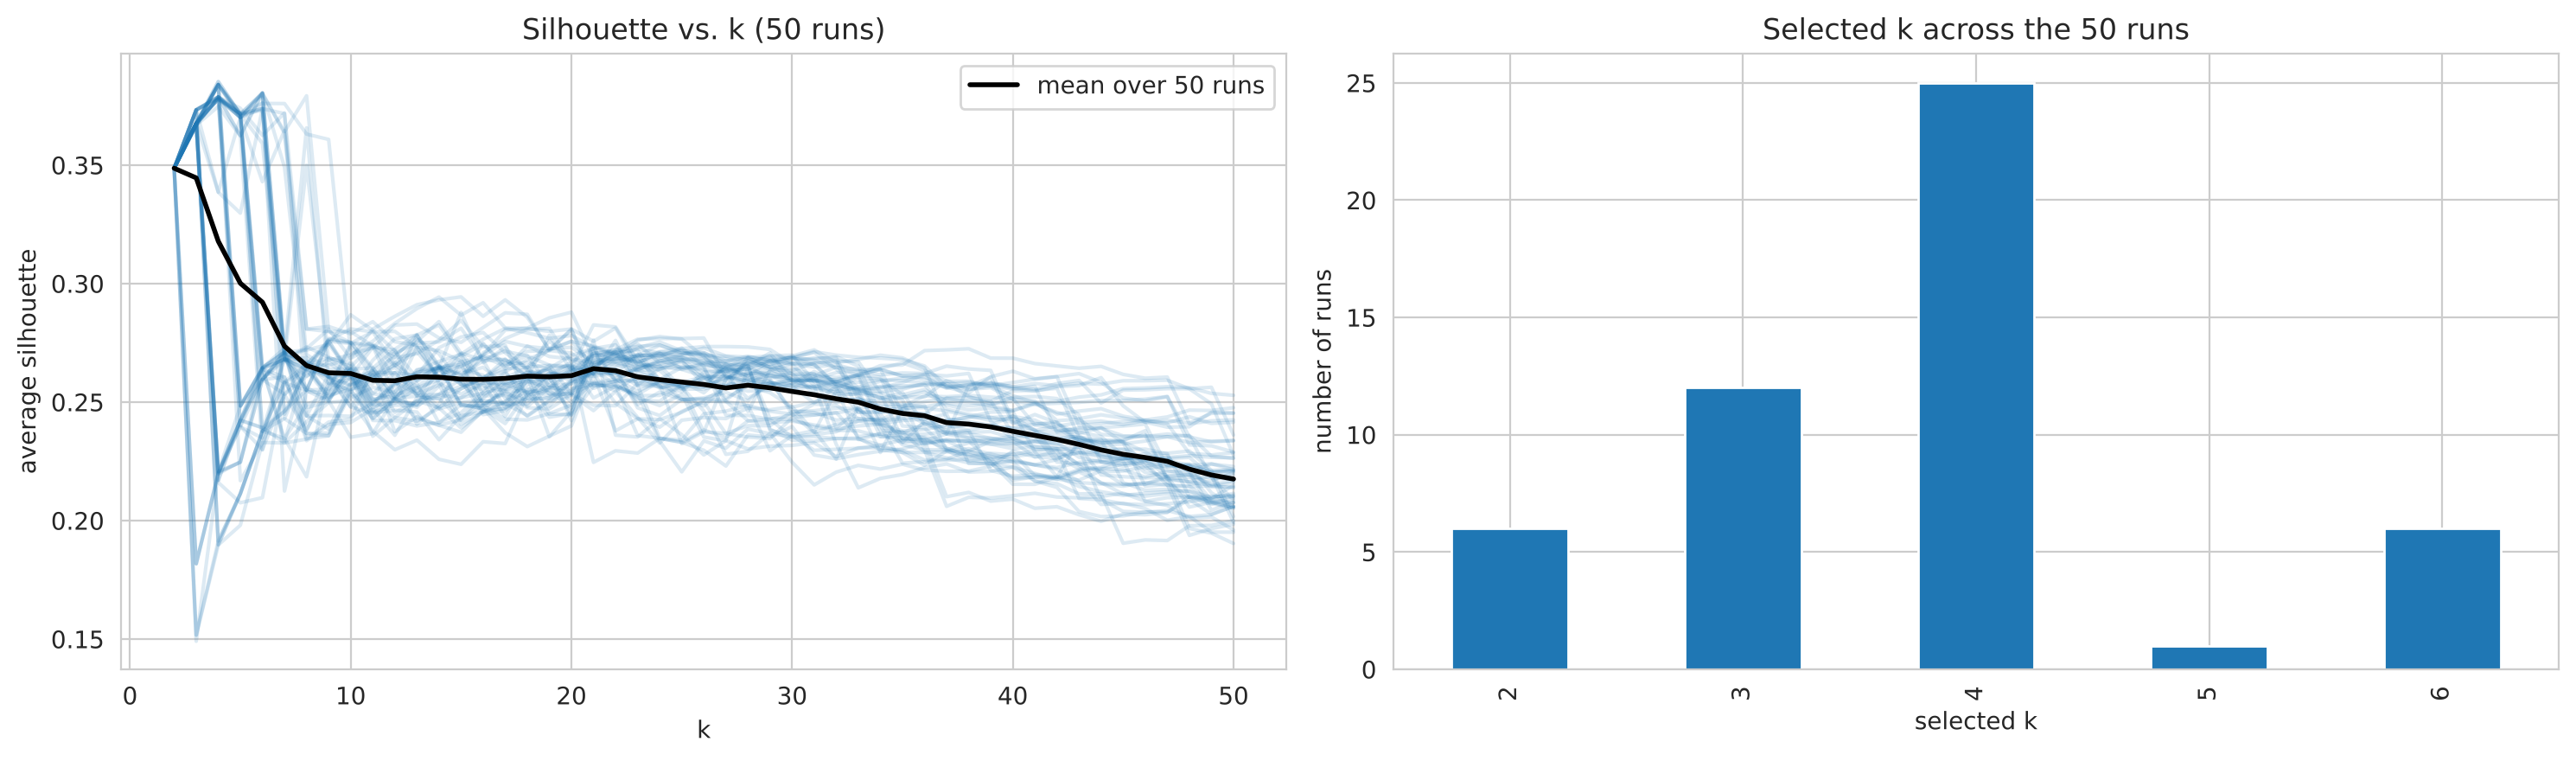

Selected k per run: [4, 4, 4, 6, 3, 4, 4, 3, 3, 4, 4, 3, 4, 4, 3, 2, 4, 4, 2, 4, 6, 4, 4, 4, 6, 3, 4, 4, 3, 4, 2, 4, 3, 4, 6, 3, 6, 6, 2, 2, 2, 4, 4, 5, 4, 4, 3, 4, 3, 3]


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for r in runs:
    axes[0].plot(K_RANGE, r["sil_curve"], color="tab:blue", alpha=0.15)
axes[0].plot(K_RANGE, np.mean([r["sil_curve"] for r in runs], axis=0), color="k", lw=2, label="mean over 50 runs")
axes[0].set_xlabel("k"); axes[0].set_ylabel("average silhouette"); axes[0].set_title("Silhouette vs. k (50 runs)")
axes[0].legend()
mc["k"].value_counts().sort_index().plot.bar(ax=axes[1], color="tab:blue")
axes[1].set_xlabel("selected k"); axes[1].set_ylabel("number of runs"); axes[1].set_title("Selected k across the 50 runs")
plt.tight_layout(); plt.show()
print("Selected k per run:", mc["k"].tolist())

### (b) Majority label triplet in each cluster (first Monte-Carlo run shown)

In [21]:
print(f"Run with seed 0: k = {runs[0]['k']}")
display(runs[0]["majority"])

Run with seed 0: k = 4


,Family,Genus,Species,size
cluster,,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3584
1,Hylidae,Hypsiboas,HypsiboasCordobae,2216
2,Hylidae,Hypsiboas,HypsiboasCinerascens,663
3,Leptodactylidae,Adenomera,AdenomeraAndre,732


### (c) Hamming distance, Hamming score and Hamming loss over the 50 runs

In [22]:
with pd.option_context("display.float_format", "{:.4f}".format):
    display(mc.head(10))
    agg = mc[["k", "avg Hamming distance", "Hamming loss", "Hamming score", "Hamming score (set-based)",
              "exact match"]].agg(["mean", "std"])
    display(agg)
print(f"Average Hamming distance over 50 runs: mean = {mc['avg Hamming distance'].mean():.4f}, "
      f"std = {mc['avg Hamming distance'].std():.4f}")

,k,silhouette,avg Hamming distance,Hamming loss,Hamming score,Hamming score (set-based),exact match
seed,,,,,,,
0,4,0.3839,0.7022,0.2341,0.7659,0.7520,0.7270
1,4,0.3852,0.7358,0.2453,0.7547,0.7323,0.6828
2,4,0.3840,0.7012,0.2337,0.7663,0.7523,0.7274
3,6,0.3802,0.5632,0.1877,0.8123,0.7965,0.7640
4,3,0.3733,0.7155,0.2385,0.7615,0.7463,0.7070
5,4,0.3840,0.7012,0.2337,0.7663,0.7523,0.7274
6,4,0.3779,0.5582,0.1861,0.8139,0.7988,0.7603
7,3,0.3677,0.8903,0.2968,0.7032,0.6830,0.6363
8,3,0.3733,0.7155,0.2385,0.7615,0.7463,0.7070


,k,avg Hamming distance,Hamming loss,Hamming score,Hamming score (set-based),exact match
mean,3.7800,0.7187,0.2396,0.7604,0.7453,0.7121
std,1.0934,0.1309,0.0436,0.0436,0.0464,0.0544


Average Hamming distance over 50 runs: mean = 0.7187, std = 0.1309


**Results.**

- **Choice of $k$ (a).** The silhouette is highest for small $k$: about 0.38 at $k = 4$ versus about 0.26 for $k \ge 10$. Over the 50 runs the selected $k$ was 4 in 25 runs, 3 in 12, 2 in 6, 6 in 6 and 5 in 1 (mean 3.78, standard deviation 1.09). The selected $k$ varies most likely because, with a single random initialization, k-means sometimes ends in a different local optimum for a given $k$, which changes that $k$'s silhouette (the spread of the curves in the plot).
- **Majority triplets (b).** The clusters are dominated by the large classes. In the first run ($k = 4$), the majority triplets are (Leptodactylidae, Adenomera, AdenomeraHylaedactylus), (Hylidae, Hypsiboas, HypsiboasCordobae), (Hylidae, Hypsiboas, HypsiboasCinerascens) and (Leptodactylidae, Adenomera, AdenomeraAndre). In that run, small groups such as `Bufonidae` and `Dendrobatidae`, and 6 of the 10 species, are not the majority in any cluster, so all of their instances get at least one wrong label.
- **Hamming metrics over the 50 Monte-Carlo runs (c):**

| Metric | Mean | Standard deviation |
|---|---|---|
| Average Hamming distance | **0.7187** | **0.1309** |
| Hamming loss | 0.2396 | 0.0436 |
| Hamming score | 0.7604 | 0.0436 |
| Hamming score (set-based) | 0.7453 | 0.0464 |
| Exact match (for reference) | 0.7121 | 0.0544 |

On average, a frog call gets about 0.72 of its 3 labels wrong when it is labeled by its cluster's majority triplet, i.e. about 76% of the labels are correct (set-based Hamming score 0.7453). This is much worse than the supervised SVMs in Question 1 (Hamming loss 0.008), which is expected: k-means does not use the labels, and the silhouette favors a few large, well-separated groups rather than one cluster per species.

# 3. ISLR 12.6.2

Dissimilarity matrix of four observations:
$$\begin{bmatrix} & 0.3 & 0.4 & 0.7 \\ 0.3 & & 0.5 & 0.8 \\ 0.4 & 0.5 & & 0.45 \\ 0.7 & 0.8 & 0.45 & \end{bmatrix}$$

**(a) Complete linkage.**
1. The smallest dissimilarity is $d(1,2) = 0.3$, so observations 1 and 2 fuse at height **0.3**.
2. Complete-linkage dissimilarities to $\{1,2\}$: $d(\{1,2\},3) = \max(0.4, 0.5) = 0.5$ and $d(\{1,2\},4) = \max(0.7, 0.8) = 0.8$. Together with $d(3,4) = 0.45$, the smallest is $0.45$, so 3 and 4 fuse at height **0.45**.
3. $d(\{1,2\},\{3,4\}) = \max(0.4, 0.7, 0.5, 0.8) = 0.8$, so the two clusters fuse at height **0.8**.

**(b) Single linkage.**
1. Observations 1 and 2 fuse at height **0.3**.
2. Single-linkage dissimilarities: $d(\{1,2\},3) = \min(0.4, 0.5) = 0.4$, $d(\{1,2\},4) = \min(0.7, 0.8) = 0.7$, $d(3,4) = 0.45$. The smallest is $0.4$, so observation 3 joins $\{1,2\}$ at height **0.4**.
3. $d(\{1,2,3\},4) = \min(0.7, 0.8, 0.45) = 0.45$, so observation 4 joins at height **0.45**.

The two dendrograms are drawn below (from the linkage matrices derived above), together with the dendrogram for part (e).

scipy complete linkage heights: [0.3  0.45 0.8 ]
scipy single linkage heights:   [0.3  0.4  0.45]


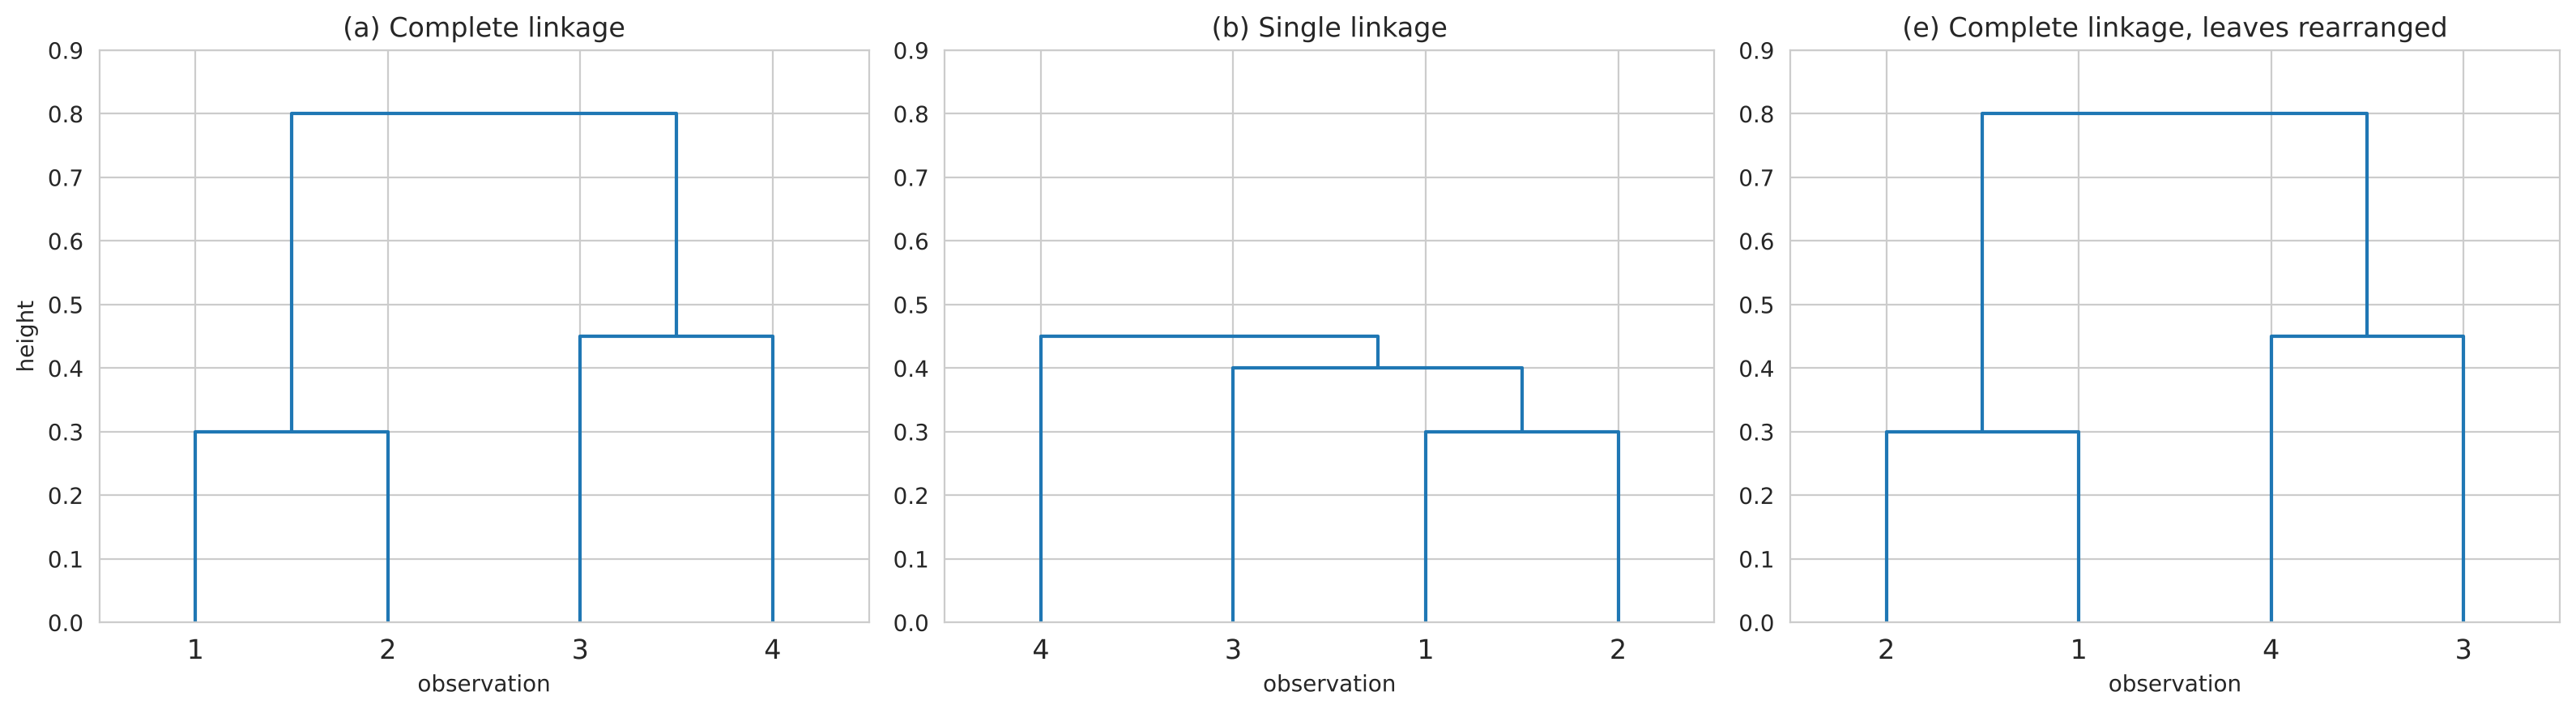

In [23]:
# Linkage matrices written out from the hand calculations: [cluster a, cluster b, height, size]
# Leaves 0..3 are observations 1..4; new clusters get ids 4, 5, 6.
Z_complete = np.array([[0, 1, 0.30, 2],    # {1,2}
                       [2, 3, 0.45, 2],    # {3,4}
                       [4, 5, 0.80, 4]])   # {1,2} + {3,4}
Z_single   = np.array([[0, 1, 0.30, 2],    # {1,2}
                       [2, 4, 0.40, 3],    # {1,2} + 3
                       [3, 5, 0.45, 4]])   # {1,2,3} + 4

# Check against scipy's hierarchical clustering on the given dissimilarities
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
D = np.array([[0, .3, .4, .7], [.3, 0, .5, .8], [.4, .5, 0, .45], [.7, .8, .45, 0]])
print("scipy complete linkage heights:", linkage(squareform(D), "complete")[:, 2])
print("scipy single linkage heights:  ", linkage(squareform(D), "single")[:, 2])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
dendrogram(Z_complete, labels=["1", "2", "3", "4"], ax=axes[0], color_threshold=0)
axes[0].set_title("(a) Complete linkage"); axes[0].set_ylabel("height")
dendrogram(Z_single, labels=["1", "2", "3", "4"], ax=axes[1], color_threshold=0)
axes[1].set_title("(b) Single linkage")
# (e): same tree as (a), with the two leaves inside each fusion swapped
Z_swapped = np.array([[1, 0, 0.30, 2], [3, 2, 0.45, 2], [4, 5, 0.80, 4]])
dendrogram(Z_swapped, labels=["1", "2", "3", "4"], ax=axes[2], color_threshold=0)
axes[2].set_title("(e) Complete linkage, leaves rearranged")
for ax in axes:
    ax.set_ylim(0, 0.9); ax.set_xlabel("observation")
plt.tight_layout(); plt.show()

**(c) Cutting the complete-linkage dendrogram into two clusters.** Cutting between heights 0.45 and 0.8 gives the clusters **$\{1, 2\}$ and $\{3, 4\}$**.

**(d) Cutting the single-linkage dendrogram into two clusters.** Cutting between heights 0.4 and 0.45 gives the clusters **$\{1, 2, 3\}$ and $\{4\}$**.

**(e) Rearranged dendrogram.** At each fusion the two branches can be swapped without changing the meaning of the dendrogram. Swapping the leaves within both fusions of the complete-linkage dendrogram gives the leaf order **2, 1, 4, 3** (right panel above). The heights and the clusters are unchanged: observations 1 and 2 still fuse at 0.3, observations 3 and 4 at 0.45, and the two pairs at 0.8.